<style>
:root{--green:#0B4F3C;--amber:#C88719;--teal:#087E8B;--red:#B42318;--ink:#20262E;--mist:#F5F8F7}
.hero{background:linear-gradient(135deg,#083D2F,#0B6E4F,#087E8B);color:white;padding:34px 38px;border-radius:18px;box-shadow:0 12px 30px rgba(8,61,47,.22)}
.hero h1{font-size:38px;margin:0 0 10px}.hero h2{font-size:20px;font-weight:400;margin:0}.badge{display:inline-block;background:#C88719;color:white;padding:6px 11px;border-radius:999px;font-weight:700;margin:15px 7px 0 0;font-size:12px}
.callout{border-left:6px solid #C88719;background:#FFF8E8;padding:15px 18px;border-radius:8px;margin:14px 0}.success{border-left:6px solid #0B6E4F;background:#EDF8F3;padding:15px 18px;border-radius:8px;margin:14px 0}.caution{border-left:6px solid #B42318;background:#FFF1F0;padding:15px 18px;border-radius:8px;margin:14px 0}
thead th{background:#0B4F3C!important;color:white!important}.jp-CodeCell .cm-line,.CodeMirror pre,div.input_area pre,div.output_area pre{white-space:pre-wrap!important;overflow-wrap:anywhere!important;word-break:break-word!important}
</style>
<div class="hero"><h1>Predicting Road Traffic Collision Severity Using Explainable Machine Learning</h1><h2>STATS19 Collision, Vehicle and Casualty Data | CRISP-DM Delivery Framework</h2><span class="badge">STATS19</span><span class="badge">CRISP-DM</span><span class="badge">Multiclass Classification</span><span class="badge">

**Data source:** UK Department for Transport, STATS19 Road Safety Open Data  
**Primary target:** Collision severity: Slight, Serious or Fatal  
**Project type:** Data science, machine learning and application development  
**Technology:** Python, pandas, NumPy, scikit-learn, Matplotlib, Seaborn, Streamlit and joblib

# 1. Project Overview

## 1.1 Background

Road traffic collisions create injuries, fatalities, property loss and pressure on emergency and transport services. Collision severity may be related to road design, environmental conditions, time, driver characteristics, vehicle characteristics and the circumstances of the collision.

This project applies statistical analysis and machine learning to official STATS19 records. The work follows the **Cross-Industry Standard Process for Data Mining (CRISP-DM)**: business understanding, data understanding, data preparation, modelling, evaluation and deployment.

## 1.2 Problem Statement

Road-safety agencies need more than collision counts. Decision-makers need to understand which recorded conditions are associated with severe outcomes and whether those characteristics can classify Slight, Serious and Fatal collisions reliably. A model with high overall accuracy may still be unsuitable if it misses the relatively rare Serious and Fatal cases.

## 1.3 Overall Aim

To develop and evaluate an explainable machine-learning solution that classifies road traffic collision severity and translates validated findings into clear road-safety decision-support information.

## 1.4 Main Research Question

> To what extent can road, environmental, temporal, driver and vehicle characteristics explain and predict road traffic collision severity, and which characteristics provide useful evidence for targeted road-safety management?

## 1.5 Specific Objectives

1. Assess the meaning, quality, completeness and suitability of the collision, vehicle and casualty data.
2. Explore the distribution of collision severity and relevant road-safety characteristics.
3. Test whether road/environment, driver/vehicle, temporal and casualty characteristics are associated with severity.
4. Prepare a reproducible, leakage-controlled modelling dataset.
5. Screen candidate classifiers, shortlist the four strongest (linear and nonlinear), add a weighted neural network, and compare all five with a no-skill baseline.
6. Evaluate performance using overall and class-level measures, with particular attention to Serious and Fatal recall.
7. Explain the selected model and investigate high-consequence model errors.
8. Develop a controlled prediction-application package if the model meets documented acceptance criteria.

## 1.6 Research Hypotheses

- **H1:** Road and environmental characteristics are associated with collision severity.
- **H2:** Driver and vehicle characteristics are associated with collision severity.
- **H3:** Collision severity varies across temporal characteristics.
- **H4:** Casualty characteristics are associated with casualty-severity outcomes.
- **H5:** Recorded characteristics provide predictive information beyond a no-skill model.
- **H6:** Class weighting improves balanced multiclass performance.
- **H7:** Nonlinear models (tree ensembles and a neural network) add predictive value beyond a linear (logistic-regression) benchmark.

## 1.7 Scope

**In scope:** official data acquisition, data dictionary, quality assessment, EDA, collision-location mapping, feature engineering, statistical tests, model comparison, class-sensitive evaluation, explainability, robustness checks, model persistence and a Streamlit prototype.

**Out of scope:** predicting whether a collision will occur, causal claims, direct integration into emergency or enforcement systems, and operational use outside Great Britain without external validation.

## 1.8 Success Criteria

The project is considered technically complete when the data can be reproduced, quality issues are documented, candidate models are compared consistently, the selected model is evaluated on untouched data, limitations are clear and the application uses the same fitted pipeline as the notebook. Operational suitability is determined separately using class-level acceptance tests.

# 2. CRISP-DM Phase 1: Business Understanding

## 2.1 Intended Users and Decision Point

The research is intended for road-safety analysts, transport planners, enforcement managers and policy stakeholders. The model predicts severity **after collision characteristics are available**. The model does not estimate collision-occurrence probability.

## 2.2 Consequences of Error

- Predicting a Serious or Fatal collision as Slight understates the recorded outcome and is the highest-consequence model error.
- Predicting a Slight collision as Serious or Fatal creates false alarms and reduces practical usefulness.
- Overall accuracy cannot be the sole selection measure because Slight collisions are expected to be more common.

## 2.3 Evaluation Priorities

The primary model-selection measure is **Macro-F1**. Supporting measures are balanced accuracy, weighted F1, overall accuracy and class-level precision and recall. Serious and Fatal recall receive explicit attention.

# 3. CRISP-DM Phase 2: Data Understanding

In [1]:
# ============================================================
# 3.1 IMPORT LIBRARIES AND SET REPRODUCIBILITY CONTROLS
# Purpose:
# Load every package used by the project, fix the random seed and configure readable notebook output.
# ============================================================

from __future__ import annotations

import json
import math
import re
import sys
import time
import warnings
from pathlib import Path
from urllib.request import Request, urlopen

import joblib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency, kruskal, mannwhitneyu

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

RANDOM_STATE = 42
ALPHA = 0.05
N_JOBS = -1
np.random.seed(RANDOM_STATE)

pd.set_option('display.max_columns', 120)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')
sns.set_theme(style='whitegrid', context='notebook')

print('Python version:', sys.version.split()[0])
print('pandas version:', pd.__version__)


Python version: 3.13.9
pandas version: 2.3.3


### Interpretation of output 3.1

The libraries loaded without error under Python 3.13.9 and pandas 2.3.3. The random seed was fixed at 42 and the significance level at 0.05, and both settings were used in every later step. These versions describe the environment in which all of the results below were produced.

For consistency and reproducibility, we fixed the random seed at 42 to ensure that random operations, such as data splitting and model initialisation, produce consistent results across repeated experiments. We also set the statistical significance level at 0.05, meaning that we used a 5% threshold for determining whether observed statistical results were significant.

In [2]:
# ============================================================
# 3.2 CREATE PROJECT FOLDERS AND REGISTER OFFICIAL DATA SOURCES
# Purpose:
# Create separate folders for raw data, analytical outputs and fitted models. Register the official five-year source files 
# in one auditable configuration.
# ============================================================

ROOT = Path.cwd()
DATA = ROOT / 'data'
OUTPUTS = ROOT / 'outputs'
MODELS = ROOT / 'models'

for folder in (DATA, OUTPUTS, MODELS):
    folder.mkdir(parents=True, exist_ok=True)

SOURCE_URLS = {
    'collisions': (
        'https://data.dft.gov.uk/road-accidents-safety-data/'
        'dft-road-casualty-statistics-collision-last-5-years.csv'
    ),
    'vehicles': (
        'https://data.dft.gov.uk/road-accidents-safety-data/'
        'dft-road-casualty-statistics-vehicle-last-5-years.csv'
    ),
    'casualties': (
        'https://data.dft.gov.uk/road-accidents-safety-data/'
        'dft-road-casualty-statistics-casualty-last-5-years.csv'
    ),
}

SOURCE_FILES = {
    name: DATA / f'{name}_last_5_years.csv'
    for name in SOURCE_URLS
}

FORCE_DOWNLOAD = False
TEST_MODE = False
TEST_ROWS = 50_000

configuration = pd.DataFrame(
    {
        'Dataset': SOURCE_URLS.keys(),
        'Local file': [str(SOURCE_FILES[name]) for name in SOURCE_URLS],
    }
)
display(configuration)


,Dataset,Local file
0,collisions,c:\Users\Isaac\Desktop\Capstone_backup\data\co...
1,vehicles,c:\Users\Isaac\Desktop\Capstone_backup\data\ve...
2,casualties,c:\Users\Isaac\Desktop\Capstone_backup\data\ca...


### Interpretation of output 3.2

Three source files were registered, one each for collisions, vehicles and casualties, all held in the project's data folder. The outputs and models folders were created at the same time. Every later cell read its data from these three paths and saved its results to the outputs and models folders.

In [3]:
# ============================================================
# 3.3 DOWNLOAD OR REUSE THE OFFICIAL SOURCE FILES
# Purpose:
# Reuse complete local files when available. Download only missing files, write through a temporary file and record the acquisition status.
# ============================================================

def download_source(name, url, destination, force=False):
    """Download one source file while protecting a valid local cache."""
    if destination.exists() and destination.stat().st_size > 0 and not force:
        return {
            'Dataset': name,
            'Status': 'Cached',
            'Size (MB)': destination.stat().st_size / 1_000_000,
            'Error': None,
        }

    temporary = destination.with_suffix(destination.suffix + '.part')
    request = Request(url, headers={'User-Agent': 'Mozilla/5.0'})

    try:
        with urlopen(request, timeout=60) as response, open(temporary, 'wb') as handle:
            while True:
                chunk = response.read(1024 * 1024)
                if not chunk:
                    break
                handle.write(chunk)
        temporary.replace(destination)
        return {
            'Dataset': name,
            'Status': 'Downloaded',
            'Size (MB)': destination.stat().st_size / 1_000_000,
            'Error': None,
        }
    except Exception as exc:
        if temporary.exists():
            temporary.unlink()
        return {
            'Dataset': name,
            'Status': 'Unavailable',
            'Size (MB)': 0.0,
            'Error': f'{type(exc).__name__}: {exc}',
        }

acquisition_log = pd.DataFrame(
    [
        download_source(name, url, SOURCE_FILES[name], FORCE_DOWNLOAD)
        for name, url in SOURCE_URLS.items()
    ]
)

display(acquisition_log)
acquisition_log.to_csv(OUTPUTS / 'data_acquisition_log.csv', index=False)

missing_required = acquisition_log.query("Status == 'Unavailable'")
if not missing_required.empty:
    missing_names = ', '.join(missing_required['Dataset'])
    raise FileNotFoundError(
        f'Missing required source files: {missing_names}. '
        f'Download the files manually into {DATA.resolve()} and rerun this cell.'
    )


,Dataset,Status,Size (MB),Error
0,collisions,Cached,97.6696,None
1,vehicles,Cached,103.7416,None
2,casualties,Cached,53.6855,None


### Interpretation of output 3.3

All three files were found in the local cache, so nothing had to be downloaded and no errors were logged. The collision file was 97.67 MB, the vehicle file 103.74 MB and the casualty file 53.69 MB. As no file was missing, the stop condition in this cell was not triggered and the analysis continued with the complete set of sources. The acquisition log was saved to `outputs/data_acquisition_log.csv`.

In [4]:
# ============================================================
# 3.4 LOAD THE THREE SOURCE TABLES
# Purpose:
# Read the collision, vehicle and casualty files, standardize column names and identify the linking keys and severity fields.
# ============================================================

def snake_case(value):
    """Convert a source column name to lowercase snake_case."""
    cleaned = re.sub(r'[^a-z0-9]+', '_', str(value).strip().lower())
    return re.sub(r'_+', '_', cleaned).strip('_')


def load_source(path):
    """Read one source CSV and standardize its column names."""
    frame = pd.read_csv(
        path,
        low_memory=False,
        nrows=TEST_ROWS if TEST_MODE else None,
    )
    frame.columns = [snake_case(column) for column in frame.columns]
    return frame


def first_existing(frame, candidates):
    """Return the first expected column found in a data frame."""
    for candidate in candidates:
        if candidate in frame.columns:
            return candidate
    raise KeyError(f'None of the expected columns were found: {candidates}')


def available(frame, candidates):
    """Return requested columns that are present in a data frame."""
    return [column for column in candidates if column in frame.columns]

collisions = load_source(SOURCE_FILES['collisions'])
vehicles = load_source(SOURCE_FILES['vehicles'])
casualties = load_source(SOURCE_FILES['casualties'])

COLLISION_ID = first_existing(collisions, ['collision_index', 'accident_index'])
COLLISION_TARGET = first_existing(
    collisions,
    ['collision_severity', 'accident_severity'],
)
VEHICLE_COLLISION_ID = first_existing(
    vehicles,
    ['collision_index', 'accident_index'],
)
CASUALTY_COLLISION_ID = first_existing(
    casualties,
    ['collision_index', 'accident_index'],
)
CASUALTY_TARGET = first_existing(casualties, ['casualty_severity'])

shape_register = pd.DataFrame(
    [
        {'Table': 'Collisions', 'Rows': len(collisions), 'Columns': collisions.shape[1]},
        {'Table': 'Vehicles', 'Rows': len(vehicles), 'Columns': vehicles.shape[1]},
        {'Table': 'Casualties', 'Rows': len(casualties), 'Columns': casualties.shape[1]},
    ]
)
display(shape_register)


,Table,Rows,Columns
0,Collisions,513801,44
1,Vehicles,937265,32
2,Casualties,652821,24


### Interpretation of output 3.4

The collision table held 513,801 rows and 44 columns, the vehicle table 937,265 rows and 32 columns, and the casualty table 652,821 rows and 24 columns. Since both the vehicle and casualty tables were larger than the collision table, some collisions had more than one vehicle or casualty record.

For this reason the collision table was used as the unit of analysis for modelling. The vehicle records were later summarised to one row per collision (Section 6.1), and the casualty records were analysed separately (Section 6.2).

In [5]:
# ============================================================
# 3.5 CHECK STRUCTURAL INTEGRITY
# Purpose:
# Confirm that collision keys are complete and unique, and that vehicle and casualty records link to valid collisions.
# ============================================================

assert collisions[COLLISION_ID].notna().all(), 'Collision key contains missing values.'
assert collisions[COLLISION_ID].is_unique, 'Collision table is not one row per collision.'
assert vehicles[VEHICLE_COLLISION_ID].notna().all(), 'Vehicle link key contains missing values.'
assert casualties[CASUALTY_COLLISION_ID].notna().all(), 'Casualty link key contains missing values.'

collision_keys = set(collisions[COLLISION_ID].astype(str))
vehicle_match = vehicles[VEHICLE_COLLISION_ID].astype(str).isin(collision_keys).mean()
casualty_match = casualties[CASUALTY_COLLISION_ID].astype(str).isin(collision_keys).mean()

integrity_results = pd.DataFrame(
    [
        {
            'Check': 'Collision key is unique',
            'Result': collisions[COLLISION_ID].is_unique,
            'Status': 'PASS' if collisions[COLLISION_ID].is_unique else 'FAIL',
        },
        {
            'Check': 'Vehicle records linked to collision',
            'Result': vehicle_match,
            'Status': 'PASS' if vehicle_match >= 0.99 else 'REVIEW',
        },
        {
            'Check': 'Casualty records linked to collision',
            'Result': casualty_match,
            'Status': 'PASS' if casualty_match >= 0.99 else 'REVIEW',
        },
    ]
)

integrity_results.to_csv(OUTPUTS / 'structural_integrity_checks.csv', index=False)
display(integrity_results)


,Check,Result,Status
0,Collision key is unique,True,PASS
1,Vehicle records linked to collision,1.0000,PASS
2,Casualty records linked to collision,1.0000,PASS


### Interpretation of output 3.5

All three integrity checks passed. Every collision key was unique, and the linkage rate was 1.0000 for both vehicle and casualty records, which meant that every record in those two tables matched a collision. The joins in Section 6.1 could therefore be made on the collision key without losing or duplicating rows.

,Table,Column,Data type,Missing records,Missing percentage,Distinct values
3,Collisions,location_easting_osgr,float64,53,0.0103,245276
4,Collisions,location_northing_osgr,float64,53,0.0103,263601
5,Collisions,longitude,float64,53,0.0103,437862
6,Collisions,latitude,float64,53,0.0103,412450


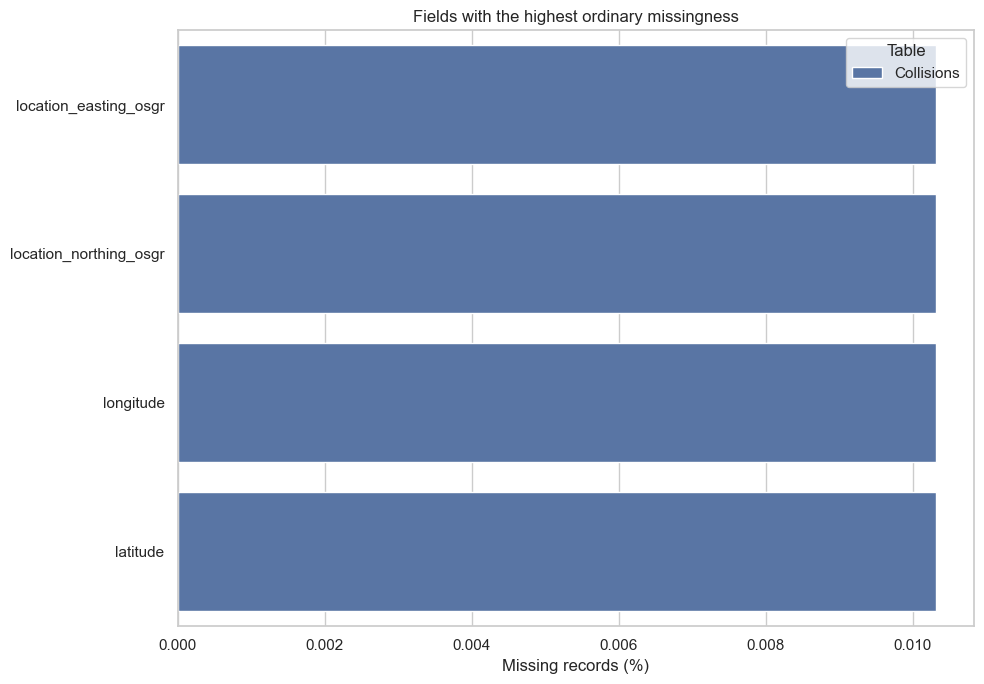

In [6]:
# ============================================================
# 3.6 PROFILE MISSING VALUES
# Purpose:
# Measure ordinary null values in every source field and visualize the 20 fields with the highest missingness.
# ============================================================

def missingness_table(frame, table_name):
    """Summarize null values and distinct values in one source table."""
    return pd.DataFrame(
        {
            'Table': table_name,
            'Column': frame.columns,
            'Data type': [str(frame[column].dtype) for column in frame.columns],
            'Missing records': [int(frame[column].isna().sum()) for column in frame.columns],
            'Missing percentage': [
                float(frame[column].isna().mean() * 100)
                for column in frame.columns
            ],
            'Distinct values': [
                int(frame[column].nunique(dropna=True))
                for column in frame.columns
            ],
        }
    )

missingness = pd.concat(
    [
        missingness_table(collisions, 'Collisions'),
        missingness_table(vehicles, 'Vehicles'),
        missingness_table(casualties, 'Casualties'),
    ],
    ignore_index=True,
).sort_values('Missing percentage', ascending=False)

missingness.to_csv(OUTPUTS / 'missingness_profile.csv', index=False)
display(missingness.query('`Missing records` > 0').head(30))

plot_missing = missingness.query('`Missing records` > 0').head(20).sort_values('Missing percentage')
if not plot_missing.empty:
    plt.figure(figsize=(10, 7))
    sns.barplot(
        data=plot_missing,
        x='Missing percentage',
        y='Column',
        hue='Table',
        dodge=False,
    )
    plt.title('Fields with the highest ordinary missingness')
    plt.xlabel('Missing records (%)')
    plt.ylabel('')
    plt.tight_layout()
    plt.show()


### Interpretation of output 3.6

Ordinary missing values were found in only four fields, all of them coordinates in the collision table: `location_easting_osgr`, `location_northing_osgr`, `longitude` and `latitude`. Each was missing for 53 records (0.0103%). No other field in any of the three tables contained blank values, as the bar chart also shows.

No records were removed on this basis. Coordinates were not used as model inputs, and the 53 collisions without a location appear as "Not mapped" in the map summary in Section 4.9.

In [7]:
# ============================================================
# 3.7 PROFILE NEGATIVE ADMINISTRATIVE CODES
# Purpose:
# Find negative numeric codes such as -1 that represent unknown or unavailable information rather than real measurements.
# ============================================================

def negative_code_profile(frame, table_name):
    """List numeric fields containing negative administrative codes."""
    rows = []
    for column in frame.select_dtypes(include=np.number).columns:
        negative_count = int((frame[column] < 0).sum())
        if negative_count == 0:
            continue
        rows.append(
            {
                'Table': table_name,
                'Column': column,
                'Negative-code records': negative_count,
                'Negative-code percentage': 100 * negative_count / len(frame),
                'Observed negative codes': sorted(
                    frame.loc[frame[column] < 0, column].dropna().unique().tolist()
                )[:10],
            }
        )
    return pd.DataFrame(rows)

negative_codes = pd.concat(
    [
        negative_code_profile(collisions, 'Collisions'),
        negative_code_profile(vehicles, 'Vehicles'),
        negative_code_profile(casualties, 'Casualties'),
    ],
    ignore_index=True,
)

negative_codes.to_csv(OUTPUTS / 'negative_code_profile.csv', index=False)
display(negative_codes.sort_values('Negative-code percentage', ascending=False).head(30))


,Table,Column,Negative-code records,Negative-code percentage,Observed negative codes
1,Collisions,local_authority_district,513607,99.9622,[-1]
0,Collisions,longitude,437236,85.0983,"[-7.486852, -7.477432, -7.455655, -7.455499, -..."
46,Vehicles,driver_distance_banding,651858,69.5490,[-1]
58,Casualties,casualty_distance_banding,428604,65.6541,[-1]
7,Collisions,junction_control,217897,42.4088,[-1]
21,Collisions,enhanced_severity_collision,204752,39.8504,[-1]
44,Vehicles,age_of_vehicle,363287,38.7603,[-1]
57,Casualties,enhanced_casualty_severity,226536,34.7011,[-1]
9,Collisions,second_road_number,178098,34.6628,[-1]
24,Vehicles,vehicle_manoeuvre_historic,278182,29.6802,[-1]


### Interpretation of output 3.7

Negative codes were far more common than blank values. In every listed field apart from longitude, the only negative value was -1; the negative longitudes were decimal coordinates such as -7.486852. The highest shares were in `local_authority_district` (99.96%), `longitude` (85.10%), `driver_distance_banding` (69.55%), `casualty_distance_banding` (65.65%) and `junction_control` (42.41%). A further group of eight fields, seven of them with the suffix `_historic`, all fell between 28.70% and 29.68%.

Several fields that are model inputs, or that feed into them, contained -1 values: `junction_control` (42.41%), `age_of_vehicle` (38.76%), `engine_capacity_cc` (25.07%), `age_of_driver` (15.18%), `trunk_road_flag` (7.07%), `junction_detail` (3.89%) and `second_road_class` (2.25%). As set out in Section 3.10, these codes were treated as unknown categories or as missing numeric values. For driver age, vehicle age and engine capacity, the negative values were masked before the summaries in Section 4.6 and before averaging in Section 6.1.

In [8]:
# ============================================================
# 3.8 MAP AND VALIDATE STATS19 CATEGORICAL CODES
# Educational-project design:
# Use an embedded, version-aware dictionary so the notebook runs offline.
# Preserve source codes, create readable labels, and fail visibly if an
# observed code has no documented label.
# ============================================================

STATS19_LABELS = {
    'road_type': {
        1: 'Roundabout', 2: 'One-way street', 3: 'Dual carriageway',
        6: 'Single carriageway', 7: 'Slip road', 9: 'Unknown road type',
        -1: 'Data missing or out of range',
    },
    'junction_detail': {
        # Earlier STATS19 coding
        0: 'Not at or within 20 metres of junction', 1: 'Roundabout',
        2: 'Mini-roundabout', 3: 'T or staggered junction', 5: 'Slip road',
        6: 'Crossroads', 7: 'More than four arms',
        8: 'Private drive or entrance', 9: 'Other junction',
        # Revised coding present in the five-year extract
        13: 'T or staggered junction', 16: 'Crossroads',
        17: 'More than four arms', 18: 'Private drive or entrance',
        19: 'Other junction', 99: 'Unknown junction detail',
        -1: 'Data missing or out of range',
    },
    'light_conditions': {
        1: 'Daylight', 4: 'Darkness - lights lit',
        5: 'Darkness - lights unlit', 6: 'Darkness - no lighting',
        7: 'Darkness - lighting unknown', -1: 'Data missing or out of range',
    },
    'weather_conditions': {
        1: 'Fine - no high winds', 2: 'Raining - no high winds',
        3: 'Snowing - no high winds', 4: 'Fine - high winds',
        5: 'Raining - high winds', 6: 'Snowing - high winds',
        7: 'Fog or mist', 8: 'Other weather', 9: 'Unknown weather',
        -1: 'Data missing or out of range',
    },
    'road_surface_conditions': {
        1: 'Dry', 2: 'Wet or damp', 3: 'Snow', 4: 'Frost or ice',
        5: 'Flood over 3 cm deep', 9: 'Unknown surface condition',
        -1: 'Data missing or out of range',
    },
    'urban_or_rural_area': {
        1: 'Urban', 2: 'Rural', 3: 'Unallocated',
        -1: 'Data missing or out of range',
    },
    'day_of_week': {
        1: 'Sunday', 2: 'Monday', 3: 'Tuesday', 4: 'Wednesday',
        5: 'Thursday', 6: 'Friday', 7: 'Saturday',
    },
}

collisions_decoded = collisions.copy()
mapping_rows = []

for variable, mapping in STATS19_LABELS.items():
    if variable not in collisions.columns:
        continue

    observed = set(
        pd.to_numeric(collisions[variable], errors='coerce')
        .dropna().astype(int).unique()
    )
    mapped_observed = observed.intersection(mapping)
    unmapped = sorted(observed.difference(mapping))

    numeric_codes = pd.to_numeric(collisions[variable], errors='coerce')
    collisions_decoded[f'{variable}_label'] = numeric_codes.map(mapping)

    mapping_rows.append({
        'Variable': variable,
        'Observed codes': len(observed),
        'Mapped codes': len(mapped_observed),
        'Unmapped codes': unmapped,
        'Complete': len(unmapped) == 0,
    })

mapping_coverage = pd.DataFrame(mapping_rows).sort_values('Variable').reset_index(drop=True)
mapping_coverage.to_csv(OUTPUTS / 'mapping_coverage.csv', index=False)
display(mapping_coverage)

incomplete = mapping_coverage.loc[~mapping_coverage['Complete']]
if not incomplete.empty:
    raise AssertionError(
        'Unmapped observed codes remain. Update STATS19_LABELS from the project data dictionary: '
        + '; '.join(
            f"{row['Variable']}={row['Unmapped codes']}"
            for _, row in incomplete.iterrows()
        )
    )

assert mapping_coverage['Complete'].all()
print('PASS: every observed code in the seven analysed categorical fields is mapped.')


,Variable,Observed codes,Mapped codes,Unmapped codes,Complete
0,day_of_week,7,7,[],True
1,junction_detail,8,8,[],True
2,light_conditions,6,6,[],True
3,road_surface_conditions,7,7,[],True
4,road_type,6,6,[],True
5,urban_or_rural_area,4,4,[],True
6,weather_conditions,10,10,[],True


PASS: every observed code in the seven analysed categorical fields is mapped.


### Interpretation of output 3.8

The code mapping was complete for all seven fields checked. In each case the number of mapped codes matched the number of observed codes: day of week 7, junction detail 8, light conditions 6, road surface 7, road type 6, urban or rural area 4 and weather 10. The PASS message confirmed that no observed code was left without a label, so the labelled tables in Section 4.4 could be produced without gaps.

## 3.9 Data-quality summary and cleaning decision register

This section brings together the integrity, missing-value, coded-value and cleaning results in a single register, together with the action taken for each issue and the reason for it.

In [9]:
# ============================================================
# 3.9 CREATE THE DATA-QUALITY SUMMARY
# Purpose:
# Summarize duplicates, missing targets, linkage coverage, ordinary missingness and coded unknown values in one evidence table.
# ============================================================
data_quality_summary = pd.DataFrame([
    {
        'Quality area': 'Duplicate collision identifiers',
        'Result': int(collisions[COLLISION_ID].duplicated().sum()),
        'Decision': 'Must be zero before modelling',
    },
    {
        'Quality area': 'Duplicate complete collision rows',
        'Result': int(collisions.duplicated().sum()),
        'Decision': 'Review before removal; do not delete automatically',
    },
    {
        'Quality area': 'Missing collision severity',
        'Result': int(collisions[COLLISION_TARGET].isna().sum()),
        'Decision': 'Exclude only from supervised modelling',
    },
    {
        'Quality area': 'Vehicle-to-collision linkage',
        'Result': f'{vehicle_match:.2%}',
        'Decision': 'Investigate if below 99%',
    },
    {
        'Quality area': 'Casualty-to-collision linkage',
        'Result': f'{casualty_match:.2%}',
        'Decision': 'Investigate if below 99%',
    },
    {
        'Quality area': 'Fields with ordinary missing values',
        'Result': int((missingness['Missing records'] > 0).sum()),
        'Decision': 'Use pipeline imputation where the field is modelled',
    },
    {
        'Quality area': 'Fields containing negative administrative codes',
        'Result': int(negative_codes['Column'].nunique()),
        'Decision': 'Treat as unknown codes, not negative measurements',
    },
])

data_quality_summary.to_csv(
    OUTPUTS / 'data_quality_summary.csv',
    index=False,
)
display(data_quality_summary)


,Quality area,Result,Decision
0,Duplicate collision identifiers,0,Must be zero before modelling
1,Duplicate complete collision rows,0,Review before removal; do not delete automatic...
2,Missing collision severity,0,Exclude only from supervised modelling
3,Vehicle-to-collision linkage,100.00%,Investigate if below 99%
4,Casualty-to-collision linkage,100.00%,Investigate if below 99%
5,Fields with ordinary missing values,4,Use pipeline imputation where the field is mod...
6,Fields containing negative administrative codes,59,"Treat as unknown codes, not negative measurements"


### Interpretation of output 3.9

The summary found no duplicate collision identifiers, no duplicate collision rows and no missing severity values, and linkage was 100.00% for both vehicles and casualties. The remaining quality issues were the four fields with blank values and the 59 fields containing negative administrative codes. No collisions had to be removed, and all 513,801 were carried into the modelling table (Section 6.3).

In [10]:
# ============================================================
# 3.10 DOCUMENT CLEANING DECISIONS
# Purpose:
# Create a formal register of each material data issue, the treatment applied and the reason for that treatment.
# ============================================================
cleaning_decisions = pd.DataFrame([
    {
        'Issue': 'Collision key duplication',
        'Treatment': 'Stop execution if the collision key is not unique',
        'Reason': 'The primary modelling unit must remain one row per collision',
    },
    {
        'Issue': 'Missing target',
        'Treatment': 'Exclude from supervised modelling only',
        'Reason': 'A known outcome is required to train and evaluate a classifier',
    },
    {
        'Issue': 'Negative administrative codes',
        'Treatment': 'Treat as unknown categories or missing numeric values',
        'Reason': 'Values such as -1 are not real road-safety measurements',
    },
    {
        'Issue': 'Missing categorical predictors',
        'Treatment': 'Impute inside the pipeline',
        'Reason': 'Fitting preprocessing only on training folds prevents leakage',
    },
    {
        'Issue': 'Rare categories in Chi-square tests',
        'Treatment': 'Collapse categories with fewer than 100 observations',
        'Reason': 'Reduces unstable expected cell counts',
    },
    {
        'Issue': 'Multiple vehicle rows per collision',
        'Treatment': 'Aggregate before joining to the collision target',
        'Reason': 'Prevents repeated collision outcomes',
    },
    {
        'Issue': 'Casualty outcome variables',
        'Treatment': 'Analyse separately from collision prediction',
        'Reason': 'Casualty severity could directly reveal the collision outcome',
    },
])
cleaning_decisions.to_csv(
    OUTPUTS / 'cleaning_decision_register.csv',
    index=False,
)
display(cleaning_decisions)


,Issue,Treatment,Reason
0,Collision key duplication,Stop execution if the collision key is not unique,The primary modelling unit must remain one row...
1,Missing target,Exclude from supervised modelling only,A known outcome is required to train and evalu...
2,Negative administrative codes,Treat as unknown categories or missing numeric...,Values such as -1 are not real road-safety mea...
3,Missing categorical predictors,Impute inside the pipeline,Fitting preprocessing only on training folds p...
4,Rare categories in Chi-square tests,Collapse categories with fewer than 100 observ...,Reduces unstable expected cell counts
5,Multiple vehicle rows per collision,Aggregate before joining to the collision target,Prevents repeated collision outcomes
6,Casualty outcome variables,Analyse separately from collision prediction,Casualty severity could directly reveal the co...


### Interpretation of output 3.10

Seven data issues were recorded, each with a treatment and a reason: collision-key duplication, missing targets, negative administrative codes, missing categorical predictors, rare categories in the Chi-square tests, multiple vehicle rows per collision and casualty outcome variables. These treatments were applied later in the notebook, namely the key assertion in Section 3.5, the collapsing of rare categories in Section 5.1, vehicle aggregation in Section 6.1, the separate casualty analysis in Section 6.2 and imputation inside the pipelines in Section 6.5.

# 4. CRISP-DM Phase 2: Exploratory Data Analysis

In [11]:
# ============================================================
# 4.1 DECODE THE SEVERITY TARGET AND ENGINEER TIME FIELDS
# Purpose:
# Validate severity codes, create readable target labels and derive month, year, hour, time band and weekend indicators.
# ============================================================

SEVERITY_MAP = {1: 'Fatal', 2: 'Serious', 3: 'Slight'}
observed_codes = set(
    pd.to_numeric(collisions[COLLISION_TARGET], errors='coerce')
    .dropna()
    .astype(int)
    .unique()
)
unexpected_codes = observed_codes - set(SEVERITY_MAP)
if unexpected_codes:
    raise ValueError(f'Unexpected severity codes: {unexpected_codes}')

collisions['severity_label'] = (
    pd.to_numeric(collisions[COLLISION_TARGET], errors='coerce')
    .map(SEVERITY_MAP)
)

if 'date' in collisions.columns:
    collisions['date_parsed'] = pd.to_datetime(
        collisions['date'], errors='coerce', dayfirst=True
    )
    collisions['month'] = collisions['date_parsed'].dt.month
    collisions['calendar_year'] = collisions['date_parsed'].dt.year

if 'time' in collisions.columns:
    parsed_time = pd.to_datetime(
        collisions['time'], format='%H:%M', errors='coerce'
    )
    collisions['hour'] = parsed_time.dt.hour
    collisions['time_band'] = pd.cut(
        collisions['hour'],
        bins=[-1, 5, 9, 15, 19, 23],
        labels=['Night', 'Morning peak', 'Daytime', 'Evening peak', 'Late evening'],
    )

if 'day_of_week' in collisions.columns:
    collisions['weekend_flag'] = collisions['day_of_week'].isin([1, 7]).astype('int8')

severity_profile = (
    collisions['severity_label']
    .value_counts()
    .rename_axis('Severity')
    .reset_index(name='Collisions')
)
severity_profile['Share'] = severity_profile['Collisions'] / severity_profile['Collisions'].sum()
display(severity_profile.style.format({'Collisions': '{:,.0f}', 'Share': '{:.1%}'}))


,Severity,Collisions,Share
0,Slight,"389,435",75.8%
1,Serious,"116,813",22.7%
2,Fatal,"7,553",1.5%


### Interpretation of output 4.1

Of the 513,801 collisions, 389,435 (75.8%) were Slight, 116,813 (22.7%) were Serious and 7,553 (1.5%) were Fatal. The classes were therefore strongly unbalanced, with Fatal collisions forming a very small minority.

The stratified split in Section 6.4 preserved these shares. The effect of the imbalance became clear in Section 7.4, where the Dummy majority baseline, which always predicts Slight, reached an overall accuracy of 0.758 but a balanced accuracy of only 0.333 and a Macro-F1 of 0.287. For this reason the models were compared mainly on Macro-F1, balanced accuracy and class recall rather than on accuracy.

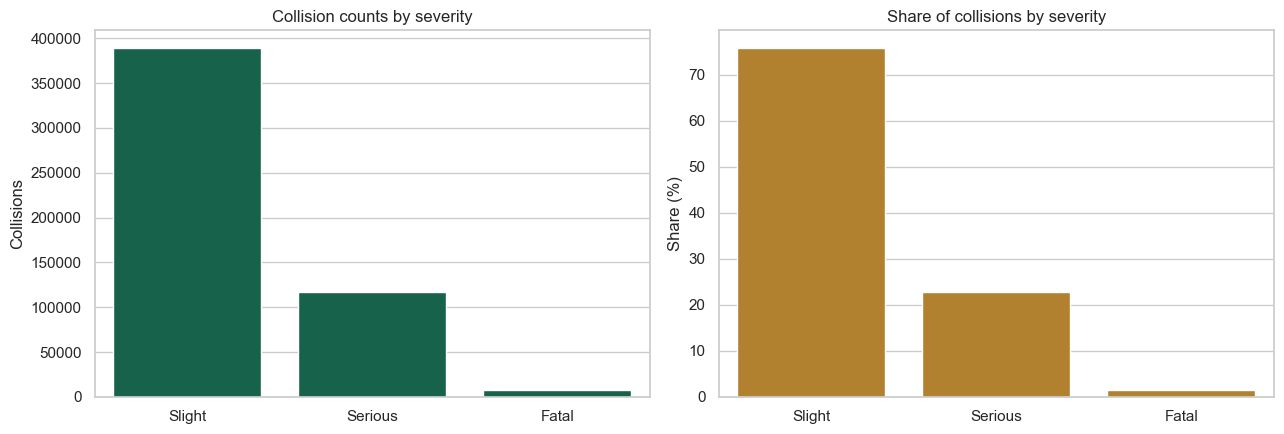

In [12]:
# ============================================================
# 4.2 VISUALIZE CLASS IMBALANCE
# Purpose:
# Show collision counts and percentages for Slight, Serious and Fatal outcomes to justify class-sensitive evaluation.
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = ['Slight', 'Serious', 'Fatal']

sns.barplot(
    data=severity_profile,
    x='Severity',
    y='Collisions',
    order=order,
    color='#0B6E4F',
    ax=axes[0],
)
axes[0].set_title('Collision counts by severity')
axes[0].set_xlabel('')
axes[0].ticklabel_format(style='plain', axis='y')

plot_share = severity_profile.copy()
plot_share['Percentage'] = plot_share['Share'] * 100
sns.barplot(
    data=plot_share,
    x='Severity',
    y='Percentage',
    order=order,
    color='#C88719',
    ax=axes[1],
)
axes[1].set_title('Share of collisions by severity')
axes[1].set_xlabel('')
axes[1].set_ylabel('Share (%)')

plt.tight_layout()
plt.show()


### Interpretation of output 4.2

The two charts present the distribution from Section 4.1, first as counts and then as percentages. In both charts the Fatal bar is barely visible beside the Slight bar.

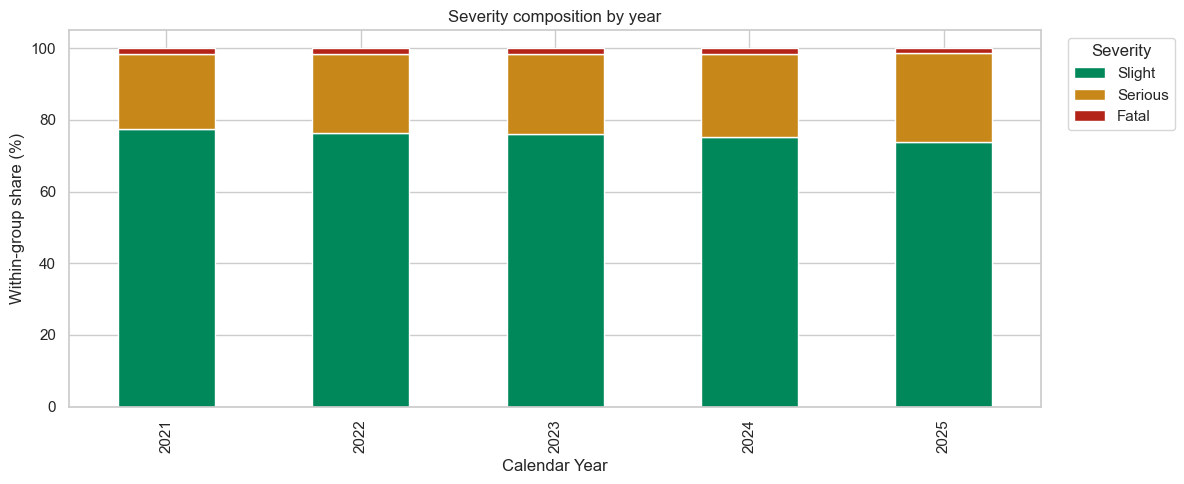

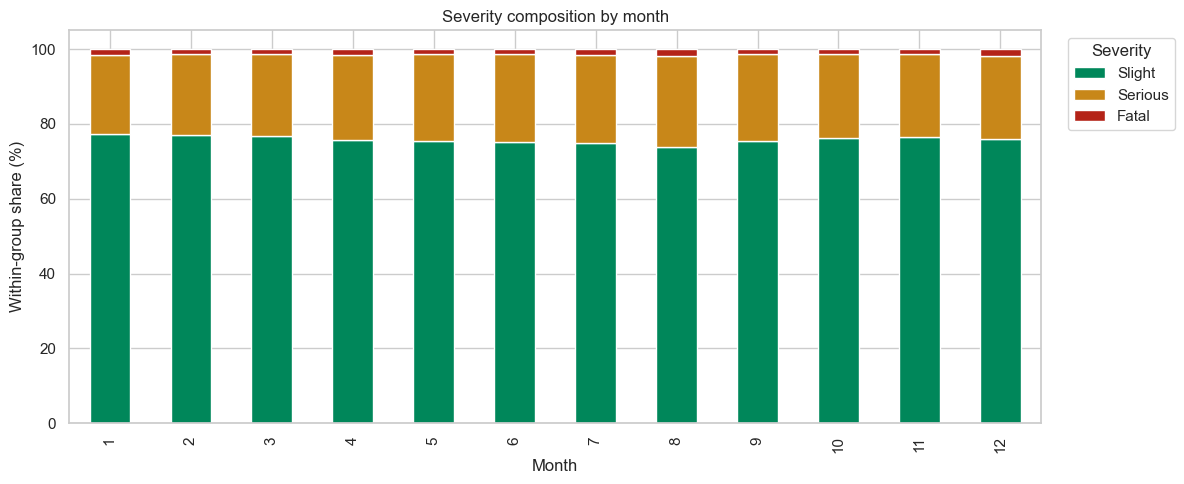

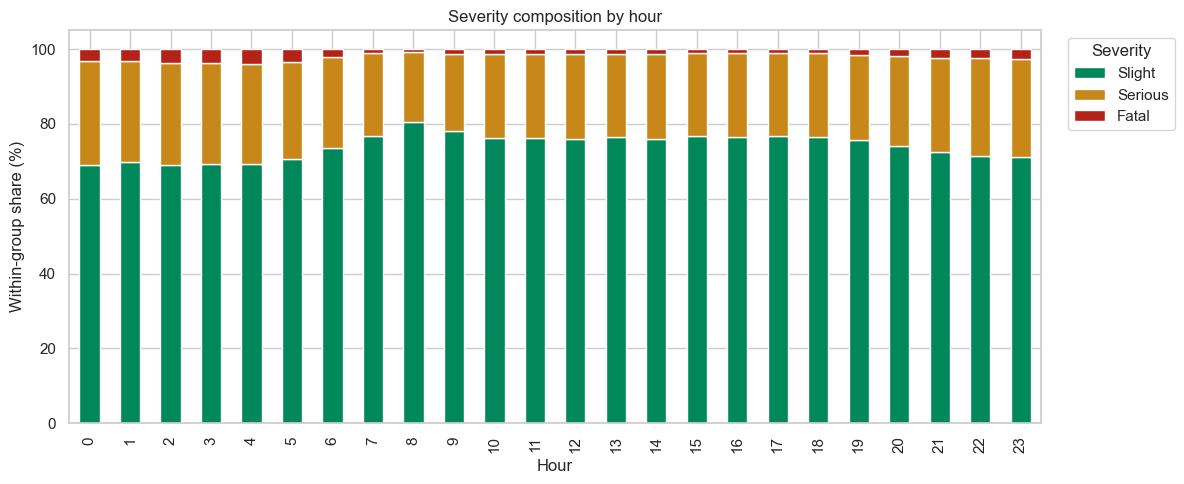

In [13]:
# ============================================================
# 4.3 EXPLORE TEMPORAL SEVERITY PATTERNS
# Purpose:
# Compare severity composition by year, month and hour. Use within-group percentages rather than raw counts alone.
# ============================================================

def severity_composition_plot(frame, variable, title, order_values=None):
    """Plot the percentage composition of severity within each category."""
    table = pd.crosstab(
        frame[variable],
        frame['severity_label'],
        normalize='index',
    ).mul(100)
    table = table.reindex(columns=['Slight', 'Serious', 'Fatal'])
    if order_values is not None:
        table = table.reindex(order_values).dropna(how='all')
    table.plot(
        kind='bar',
        stacked=True,
        figsize=(12, 5),
        color=['#00875A', '#C88719', '#B42318'],
    )
    plt.title(title)
    plt.xlabel(variable.replace('_', ' ').title())
    plt.ylabel('Within-group share (%)')
    plt.legend(title='Severity', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

if 'calendar_year' in collisions.columns:
    severity_composition_plot(collisions, 'calendar_year', 'Severity composition by year')
if 'month' in collisions.columns:
    severity_composition_plot(collisions, 'month', 'Severity composition by month', range(1, 13))
if 'hour' in collisions.columns:
    severity_composition_plot(collisions, 'hour', 'Severity composition by hour', range(24))


### Interpretation of output 4.3

The three charts show how the mix of severities changed by year, month and hour. Across the years, the Slight share fell slightly from 2021 to 2025 while the Serious share grew, and the Fatal share remained a thin band throughout. Differences between months were small, although the Slight share was lowest in month 8 and the Fatal band was a little wider in months 8 and 12.

The hourly chart showed the clearest pattern. In hours 0 to 5 the Slight segment was at its smallest, at around 69 to 70% on the chart axis, and the Fatal segment at its widest. The Slight share peaked at around 80% at hour 8 and narrowed again from hour 19 to hour 23. These patterns agree with the H3 tests in Section 5.2, where hour had the largest temporal Cramér's V (0.0496) and month the smallest (0.0160). Hour and time band were kept as model inputs, whereas calendar year was not; the latest year, 2025, was instead held out for the robustness test in Section 8.6.

In [14]:
# ============================================================
# 4.4 EXPLORE ROAD AND ENVIRONMENTAL SEVERITY PROFILES
# Purpose:
# Calculate Serious/Fatal shares for decoded road and environmental categories with at least 250 observations.
# ============================================================

def severe_rate_table(frame, variable, minimum_records=250):
    """Calculate the Serious/Fatal share for each category."""
    working = frame[[variable, 'severity_label']].copy()
    working['Severe'] = working['severity_label'].isin(['Serious', 'Fatal'])
    result = (
        working.groupby(variable, dropna=False)
        .agg(
            Collisions=('Severe', 'size'),
            Severe_collisions=('Severe', 'sum'),
            Severe_share=('Severe', 'mean'),
        )
        .reset_index()
    )
    result['Severe share (%)'] = result['Severe_share'] * 100
    return result.query('Collisions >= @minimum_records').sort_values(
        'Severe share (%)', ascending=False
    )

labelled_factors = [
    'road_type_label',
    'junction_detail_label',
    'light_conditions_label',
    'weather_conditions_label',
    'road_surface_conditions_label',
    'urban_or_rural_area_label',
]

for factor in labelled_factors:
    if factor not in collisions_decoded.columns:
        continue
    # Add the severity label and engineered target to the decoded copy.
    collisions_decoded['severity_label'] = collisions['severity_label']
    profile = severe_rate_table(collisions_decoded, factor)
    print('\n', factor.replace('_label', '').replace('_', ' ').title())
    display(profile.head(15))



 Road Type


,road_type_label,Collisions,Severe_collisions,Severe_share,Severe share (%)
3,Single carriageway,373065,96767,0.2594,25.9384
0,Dual carriageway,76119,17426,0.2289,22.8931
4,Slip road,8829,1584,0.1794,17.9409
1,One-way street,11550,2050,0.1775,17.7489
2,Roundabout,31178,5365,0.1721,17.2076
5,Unknown road type,13060,1174,0.0899,8.9893



 Junction Detail


,junction_detail_label,Collisions,Severe_collisions,Severe_share,Severe share (%)
3,Not at or within 20 metres of junction,252021,65078,0.2582,25.8225
5,Private drive or entrance,11147,2712,0.2433,24.3294
4,Other junction,31096,7564,0.2432,24.3247
6,T or staggered junction,142597,33502,0.2349,23.4942
0,Crossroads,47572,10869,0.2285,22.8475
2,More than four arms,7957,1808,0.2272,22.7221
1,Data missing or out of range,19982,2756,0.1379,13.7924
7,Unknown junction detail,1429,77,0.0539,5.3884



 Light Conditions


,light_conditions_label,Collisions,Severe_collisions,Severe_share,Severe share (%)
3,Darkness - no lighting,27438,9589,0.3495,34.9479
2,Darkness - lights unlit,3706,1080,0.2914,29.1419
1,Darkness - lights lit,105834,26578,0.2511,25.1129
5,Daylight,368193,85402,0.2319,23.1949
0,Darkness - lighting unknown,8596,1707,0.1986,19.8581


... (2 outputs left out)


 Road Surface Conditions


,road_surface_conditions_label,Collisions,Severe_collisions,Severe_share,Severe share (%)
2,Flood over 3 cm deep,788,215,0.2728,27.2843
6,Wet or damp,120572,30572,0.2536,25.3558
1,Dry,374268,90900,0.2429,24.2874
4,Snow,1257,289,0.2299,22.9912
3,Frost or ice,6668,1510,0.2265,22.6455
0,Data missing or out of range,3527,403,0.1143,11.4261
5,Unknown surface condition,6721,477,0.0710,7.0972



 Urban Or Rural Area


,urban_or_rural_area_label,Collisions,Severe_collisions,Severe_share,Severe share (%)
1,Rural,168429,49457,0.2936,29.3637
3,Urban,345314,74891,0.2169,21.6878


### Interpretation of output 4.4

The labelled profiles compared the Serious/Fatal share across categories with at least 250 collisions. The highest share in each field was found for single carriageway roads (25.94%), locations not at or within 20 metres of a junction (25.82%), "Darkness - no lighting" (34.95%), "Fine - high winds" (29.74%), flooded surfaces over 3 cm deep (27.28%, from 788 collisions) and rural areas (29.36%, compared with 21.69% for urban areas). Daylight collisions had a severe share of 23.19%.

In road type, junction detail, weather and road surface, the lowest shares belonged to the unknown or missing categories, for example 8.99% for unknown road type and 5.39% for unknown junction detail. All six fields were tested formally in Section 5.2, where each was significant, and all six were used as model inputs.

## 4.5 Extended collision, vehicle and casualty exploration

The following tables extend the descriptive analysis to speed limit, the raw coded fields, and the vehicle and casualty tables. Each table gives both the number of collisions and the share within each group that were Serious or Fatal.


 Speed Limit


,speed_limit,Collisions,Severe_collisions,Severe_share,Severe share (%)
5,60,62703,21628,0.3449,34.4928
4,50,22666,6425,0.2835,28.3464
3,40,44750,11495,0.2569,25.6872
6,70,28258,6956,0.2462,24.6160
2,30,267325,60547,0.2265,22.6492
1,20,88096,17314,0.1965,19.6536



 Light Conditions


,light_conditions,Collisions,Severe_collisions,Severe_share,Severe share (%)
4,6,27438,9589,0.3495,34.9479
3,5,3706,1080,0.2914,29.1419
2,4,105834,26578,0.2511,25.1129
1,1,368193,85402,0.2319,23.1949
5,7,8596,1707,0.1986,19.8581



 Weather Conditions


,weather_conditions,Collisions,Severe_collisions,Severe_share,Severe share (%)
4,4,4472,1330,0.2974,29.7406
7,7,2128,597,0.2805,28.0545
5,5,5173,1385,0.2677,26.7736
1,1,413632,102325,0.2474,24.7382
2,2,55834,13404,0.2401,24.0069
3,3,1791,406,0.2267,22.6689
8,8,15955,3164,0.1983,19.8308
9,9,14566,1707,0.1172,11.7191


... (2 outputs left out)


 Junction Detail


,junction_detail,Collisions,Severe_collisions,Severe_share,Severe share (%)
1,0,252021,65078,0.2582,25.8225
5,18,11147,2712,0.2433,24.3294
6,19,31096,7564,0.2432,24.3247
2,13,142597,33502,0.2349,23.4942
3,16,47572,10869,0.2285,22.8475
4,17,7957,1808,0.2272,22.7221
0,-1,19982,2756,0.1379,13.7924
7,99,1429,77,0.0539,5.3884



 Urban Or Rural Area


,urban_or_rural_area,Collisions,Severe_collisions,Severe_share,Severe share (%)
2,2,168429,49457,0.2936,29.3637
1,1,345314,74891,0.2169,21.6878


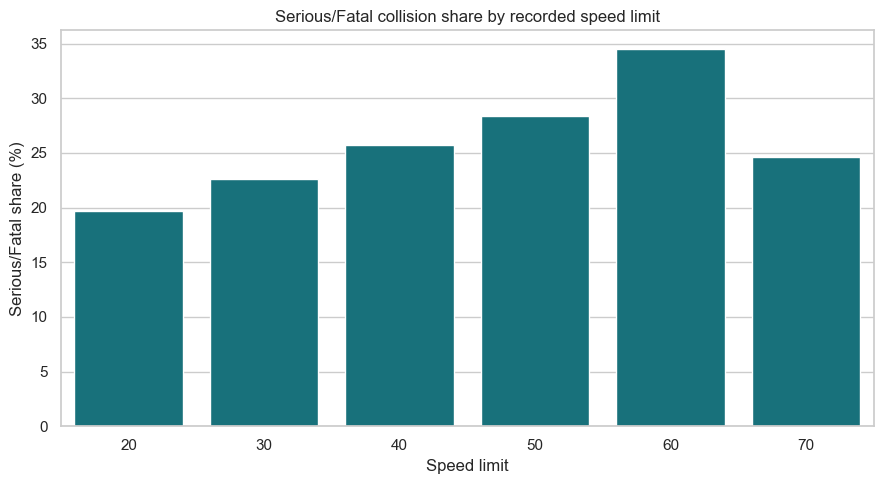

In [15]:
# ============================================================
# 4.5 EXPLORE SEVERITY BY SPEED, LIGHT, WEATHER AND ROAD SURFACE
# Purpose:
# Compare collision volume and the Serious/Fatal share across high-priority road and environmental characteristics.
# ============================================================
priority_eda_features = available(
    collisions,
    [
        'speed_limit',
        'light_conditions',
        'weather_conditions',
        'road_surface_conditions',
        'junction_detail',
        'urban_or_rural_area',
    ],
)

eda_profiles = {}
for feature in priority_eda_features:
    profile = severe_rate_table(
        collisions,
        feature,
        minimum_records=250,
    )
    eda_profiles[feature] = profile
    print('\n', feature.replace('_', ' ').title())
    display(profile.head(15))

# Create one management-friendly chart for the speed environment.
if 'speed_limit' in eda_profiles and not eda_profiles['speed_limit'].empty:
    plot_data = eda_profiles['speed_limit'].sort_values('speed_limit')
    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=plot_data,
        x='speed_limit',
        y='Severe share (%)',
        color='#087E8B',
    )
    plt.title('Serious/Fatal collision share by recorded speed limit')
    plt.xlabel('Speed limit')
    plt.ylabel('Serious/Fatal share (%)')
    plt.tight_layout()
    plt.show()


### Interpretation of output 4.5

The severe share rose with the speed limit, from 19.65% at a limit of 20 to 22.65% at 30, 25.69% at 40, 28.35% at 50 and 34.49% at 60. The limit of 70 was the exception, at 24.62%, which placed it below both 40 and 50. The 30 group contained by far the largest number of collisions (267,325).

The remaining tables repeated the Section 4.4 profiles using the raw codes, and the figures matched the labelled results exactly; light code 6, for example, had 27,438 collisions and a severe share of 34.9479%, the same as "Darkness - no lighting". Speed limit went on to show the largest Cramér's V among the road and environment factors (0.0904, Section 5.2) and the largest standardised residual (+48.99 for Fatal collisions at a limit of 60, Section 5.4).

In [16]:
# ============================================================
# 4.6 EXPLORE DRIVER AND VEHICLE CHARACTERISTICS
# Purpose:
# Summarize driver age, vehicle age, vehicle type and vehicle manoeuvre before aggregation to collision level.
# ============================================================
vehicle_eda_rows = []
for feature in available(
    vehicles,
    ['vehicle_type', 'vehicle_manoeuvre', 'sex_of_driver', 'age_band_of_driver'],
):
    top = (
        vehicles[feature]
        .value_counts(dropna=False)
        .head(15)
        .rename_axis('Category')
        .reset_index(name='Vehicle records')
    )
    top.insert(0, 'Feature', feature)
    vehicle_eda_rows.append(top)

vehicle_eda = pd.concat(vehicle_eda_rows, ignore_index=True)
vehicle_eda.to_csv(OUTPUTS / 'vehicle_eda_top_categories.csv', index=False)
display(vehicle_eda)

for feature in available(vehicles, ['age_of_driver', 'age_of_vehicle']):
    numeric = pd.to_numeric(vehicles[feature], errors='coerce')
    numeric = numeric.mask(numeric < 0)
    print(feature, numeric.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(2).to_dict())


,Feature,Category,Vehicle records
0,vehicle_type,9,637681
1,vehicle_type,1,81486
2,vehicle_type,19,60309
3,vehicle_type,3,44795
4,vehicle_type,5,23011
5,vehicle_type,8,15362
6,vehicle_type,11,15100
7,vehicle_type,21,13247
8,vehicle_type,4,9590
9,vehicle_type,33,6901


age_of_driver {'count': 795025.0, 'mean': 41.2, 'std': 16.87, 'min': 1.0, '25%': 28.0, '50%': 39.0, '75%': 53.0, '90%': 65.0, 'max': 105.0}
age_of_vehicle {'count': 573978.0, 'mean': 8.59, 'std': 5.86, 'min': 0.0, '25%': 4.0, '50%': 8.0, '75%': 13.0, '90%': 16.0, 'max': 123.0}


### Interpretation of output 4.6

The vehicle table contained 937,265 records. A single code dominated vehicle type (code 9, with 637,681 records) and another dominated vehicle manoeuvre (code 19, with 480,128). For driver sex, code 1 accounted for 575,771 records, code 2 for 239,124 and code 3 for 114,525. The most frequent driver age band was code 6 (187,204 records), while 142,240 records had no age band (code -1).

Once the negative codes were excluded, driver age was available for 795,025 records, with a mean of 41.2 and a median of 39 (interquartile range 28 to 53). Vehicle age was available for 573,978 records, with a median of 8 (interquartile range 4 to 13) and a maximum of 123.

These fields were summarised to collision level in Section 6.1. In the H2 tests (Section 6.2), first-vehicle manoeuvre (V = 0.1175) and first-vehicle type (V = 0.1082) gave the two strongest driver and vehicle associations.

In [17]:
# ============================================================
# 4.7 EXPLORE CASUALTY CHARACTERISTICS
# Purpose:
# Summarize casualty class, age band, casualty type and sex before conducting casualty-level hypothesis tests.
# ============================================================
casualty_eda_rows = []
for feature in available(
    casualties,
    ['casualty_class', 'age_band_of_casualty', 'casualty_type', 'sex_of_casualty'],
):
    top = (
        casualties[feature]
        .value_counts(dropna=False)
        .head(20)
        .rename_axis('Category')
        .reset_index(name='Casualty records')
    )
    top.insert(0, 'Feature', feature)
    casualty_eda_rows.append(top)

casualty_eda = pd.concat(casualty_eda_rows, ignore_index=True)
casualty_eda.to_csv(OUTPUTS / 'casualty_eda_top_categories.csv', index=False)
display(casualty_eda)


,Feature,Category,Casualty records
0,casualty_class,1,432883
1,casualty_class,2,125540
2,casualty_class,3,94398
3,age_band_of_casualty,6,132804
4,age_band_of_casualty,7,100841
5,age_band_of_casualty,8,81997
6,age_band_of_casualty,5,70305
7,age_band_of_casualty,4,68000
8,age_band_of_casualty,9,64371
9,age_band_of_casualty,10,33977


### Interpretation of output 4.7

The casualty table contained 652,821 records. The most frequent codes were casualty class 1 (432,883 records), casualty age band 6 (132,804), casualty type 9 (347,393) and sex code 1 (397,917). Casualty type code 0 and casualty class code 3 had the same count, 94,398.

These fields were tested against casualty severity in Section 6.2 (H4), where casualty type produced the largest Cramér's V in the study (0.1613). They were not used as inputs to the collision model, and the predictor list in Section 6.3 contains no casualty fields.

In [18]:
# ============================================================
# 4.8 GENERATE PLAIN-ENGLISH EDA FINDINGS
# Purpose:
# Convert key descriptive outputs into understandable evidence statements without making causal claims.
# ============================================================
severity_lookup = severity_profile.set_index('Severity')
eda_findings = []

for severity in ['Slight', 'Serious', 'Fatal']:
    if severity in severity_lookup.index:
        eda_findings.append(
            f"{severity} collisions represented "
            f"{severity_lookup.loc[severity, 'Share']:.1%} of the analysed collisions."
        )

if 'speed_limit' in eda_profiles and not eda_profiles['speed_limit'].empty:
    highest = eda_profiles['speed_limit'].iloc[0]
    eda_findings.append(
        f"Among speed-limit groups with at least 250 collisions, the highest "
        f"observed Serious/Fatal share occurred at code/value "
        f"{highest['speed_limit']} ({highest['Severe share (%)']:.1f}%)."
    )

for finding in eda_findings:
    print('•', finding)

print(
    '\nInterpretation rule: these are patterns among recorded collisions. '
    'They are not exposure-adjusted risks and do not prove causation.'
)


• Slight collisions represented 75.8% of the analysed collisions.
• Serious collisions represented 22.7% of the analysed collisions.
• Fatal collisions represented 1.5% of the analysed collisions.
• Among speed-limit groups with at least 250 collisions, the highest observed Serious/Fatal share occurred at code/value 60.0 (34.5%).

Interpretation rule: these are patterns among recorded collisions. They are not exposure-adjusted risks and do not prove causation.


### Interpretation of output 4.8

The generated statements agreed with the tables above. Slight collisions made up 75.8% of the total, Serious collisions 22.7% and Fatal collisions 1.5%, and the highest severe share among speed-limit groups with at least 250 collisions was 34.5%, at a limit of 60. The cell also printed the rule that these are patterns among recorded collisions, not exposure-adjusted risks, and that they do not prove causation. That rule applies to all of the descriptive results in Section 4.

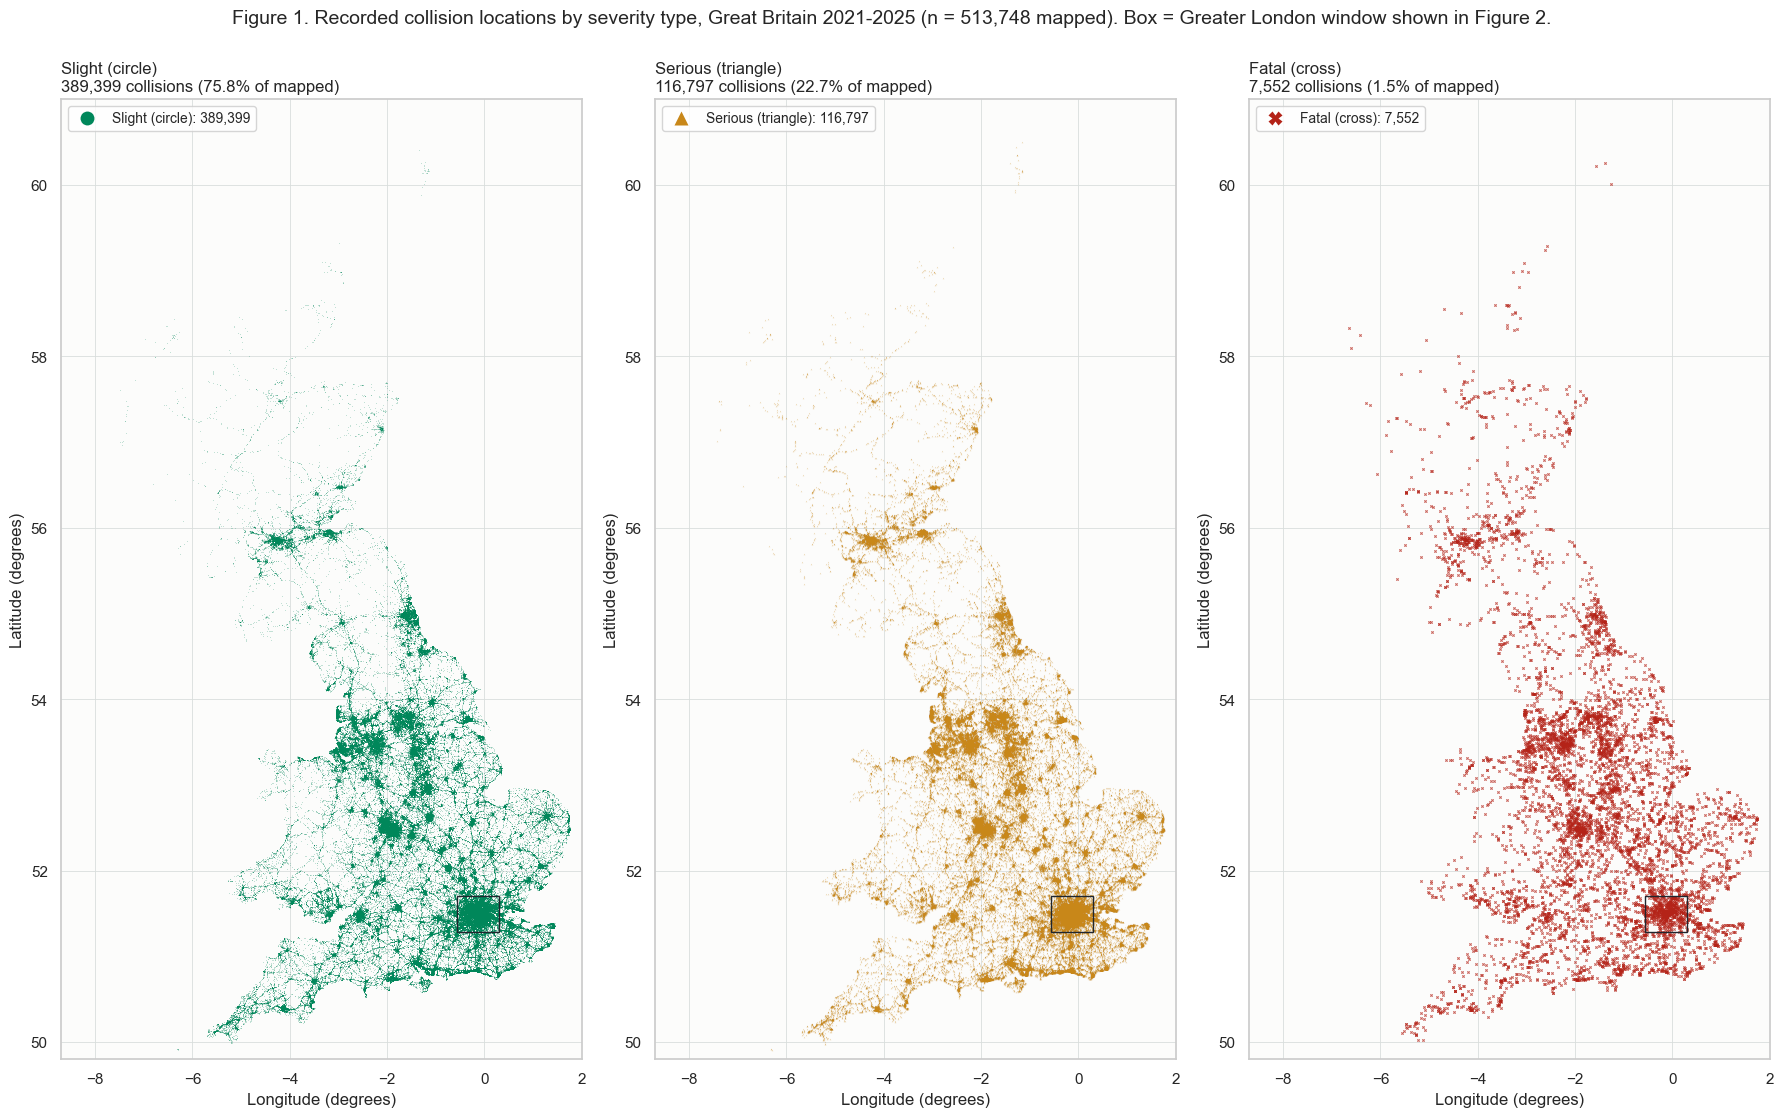

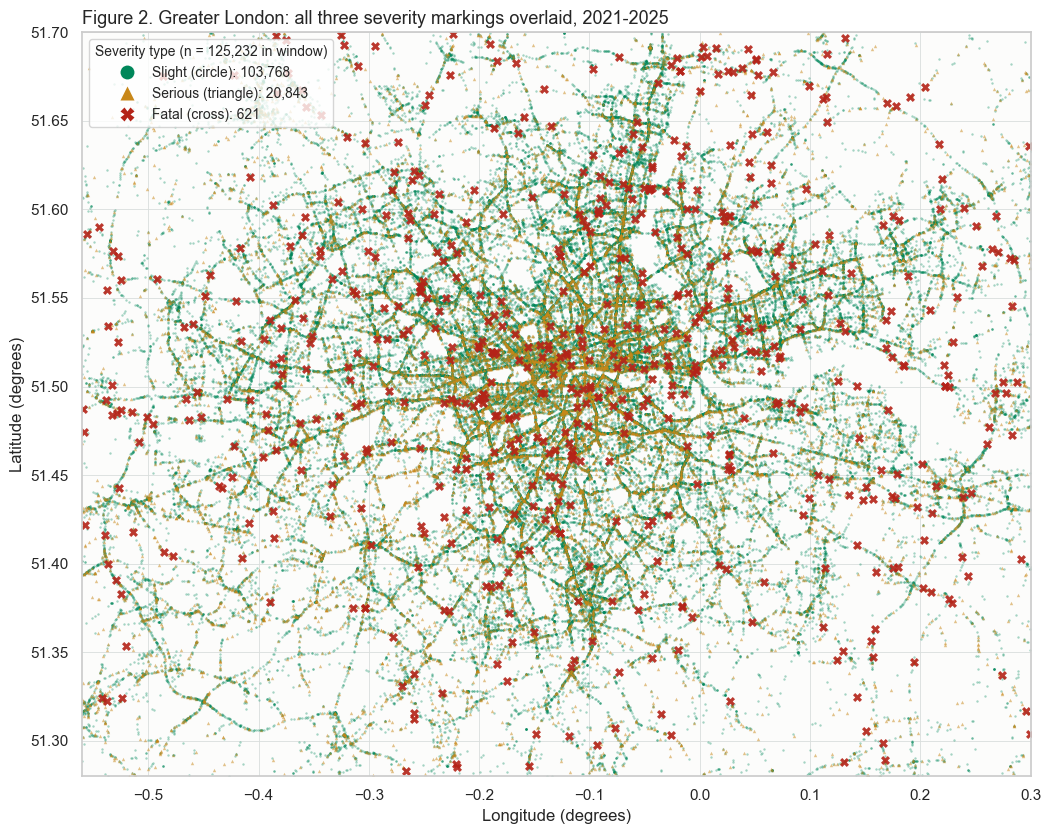

Severity,Collisions,Mapped,Not mapped,Mapped (%),Inside London window,London share of mapped (%)
Slight,"389,435","389,399",36,99.99%,"103,768",26.6%
Serious,"116,813","116,797",16,99.99%,"20,843",17.8%
Fatal,"7,553","7,552",1,99.99%,621,8.2%
All collisions,"513,801","513,748",53,99.99%,"125,232",24.4%


In [19]:
# ============================================================
# 4.9 MAP COLLISION LOCATIONS BY SEVERITY TYPE
# Purpose:
# Plot every collision with valid coordinates using a different marking for
# each severity type: Slight = green circle, Serious = amber triangle and
# Fatal = red cross.
# Figure 1 gives each type its own national panel (same scale and extent) so
# 389,000 Slight points cannot hide the 7,500 Fatal points, and the rare Fatal
# points cannot visually swamp the common Slight ones.
# Figure 2 overlays all three markings in Greater London, where individual
# roads are visible; rarer types are drawn last so they stay visible.
# Coordinates are used for description only; they remain excluded from the
# predictive model.
# ============================================================

SEVERITY_ORDER_MAP = ['Slight', 'Serious', 'Fatal']
SEVERITY_STYLE = {
    # marker shape + colour + size together give each type a distinct marking
    'Slight': {'color': '#00875A', 'marker': 'o', 'label': 'Slight (circle)',
               'size_national': 0.4, 'alpha_national': 0.20,
               'size_zoom': 3.0, 'alpha_zoom': 0.35},
    'Serious': {'color': '#C88719', 'marker': '^', 'label': 'Serious (triangle)',
                'size_national': 1.2, 'alpha_national': 0.35,
                'size_zoom': 6.0, 'alpha_zoom': 0.50},
    'Fatal': {'color': '#B42318', 'marker': 'X', 'label': 'Fatal (cross)',
              'size_national': 5.0, 'alpha_national': 0.70,
              'size_zoom': 42.0, 'alpha_zoom': 0.90},
}
GB_WINDOW = {'longitude': (-8.7, 2.0), 'latitude': (49.8, 61.0)}
LONDON_WINDOW = {'longitude': (-0.56, 0.30), 'latitude': (51.28, 51.70)}


def inside(frame, window):
    """Flag records whose coordinates fall inside a longitude/latitude window."""
    return (
        frame['longitude'].between(*window['longitude'])
        & frame['latitude'].between(*window['latitude'])
    )


locations = collisions[['longitude', 'latitude', 'severity_label']].copy()
for coordinate in ('longitude', 'latitude'):
    locations[coordinate] = pd.to_numeric(locations[coordinate], errors='coerce')
locations['Mapped'] = inside(locations, GB_WINDOW)
locations['In London window'] = locations['Mapped'] & inside(locations, LONDON_WINDOW)
mapped_locations = locations[locations['Mapped']]


def location_row(label, frame):
    """Summarize coordinate coverage and the London share for one group."""
    mapped = int(frame['Mapped'].sum())
    london = int(frame['In London window'].sum())
    return {
        'Severity': label,
        'Collisions': len(frame),
        'Mapped': mapped,
        'Not mapped': len(frame) - mapped,
        'Mapped (%)': 100 * mapped / len(frame),
        'Inside London window': london,
        'London share of mapped (%)': 100 * london / mapped if mapped else np.nan,
    }


location_summary = pd.DataFrame(
    [
        location_row(severity, locations[locations['severity_label'] == severity])
        for severity in SEVERITY_ORDER_MAP
    ]
    + [location_row('All collisions', locations)]
)
location_summary.to_csv(OUTPUTS / 'collision_location_summary.csv', index=False)

first_year = int(collisions['calendar_year'].min())
last_year = int(collisions['calendar_year'].max())


def plot_severity(ax, frame, severity, scale):
    """Draw one severity type with its own marker, colour and size."""
    style = SEVERITY_STYLE[severity]
    subset = frame[frame['severity_label'] == severity]
    ax.scatter(
        subset['longitude'],
        subset['latitude'],
        s=style[f'size_{scale}'],
        c=style['color'],
        marker=style['marker'],
        alpha=style[f'alpha_{scale}'],
        linewidths=0,
        rasterized=True,
    )


def format_map_axis(ax, window, title, fontsize=13):
    """Apply limits, an approximately equal-distance aspect and quiet styling."""
    ax.set_xlim(window['longitude'])
    ax.set_ylim(window['latitude'])
    ax.set_aspect(1 / np.cos(np.deg2rad(np.mean(window['latitude']))))
    ax.set_title(title, fontsize=fontsize, loc='left')
    ax.set_xlabel('Longitude (degrees)')
    ax.set_ylabel('Latitude (degrees)')
    ax.grid(color='#D9DEDC', linewidth=0.6)
    ax.set_facecolor('#FCFCFB')


def legend_handles(frame):
    """Build legend entries that show each marker shape and its record count."""
    return [
        Line2D(
            [0], [0],
            marker=SEVERITY_STYLE[severity]['marker'],
            color='none',
            markerfacecolor=SEVERITY_STYLE[severity]['color'],
            markeredgecolor='none',
            markersize=10,
            label=(
                f"{SEVERITY_STYLE[severity]['label']}: "
                f"{int((frame['severity_label'] == severity).sum()):,}"
            ),
        )
        for severity in SEVERITY_ORDER_MAP
    ]


# Figure 1: national view, one panel per severity type on a common extent.
fig, axes = plt.subplots(1, 3, figsize=(18, 11.5))
for ax, severity in zip(axes, SEVERITY_ORDER_MAP):
    plot_severity(ax, mapped_locations, severity, 'national')
    count = int((mapped_locations['severity_label'] == severity).sum())
    format_map_axis(
        ax,
        GB_WINDOW,
        f"{SEVERITY_STYLE[severity]['label']}\n"
        f'{count:,} collisions ({count / len(mapped_locations):.1%} of mapped)',
        fontsize=12,
    )
    ax.add_patch(
        Rectangle(
            (LONDON_WINDOW['longitude'][0], LONDON_WINDOW['latitude'][0]),
            np.diff(LONDON_WINDOW['longitude'])[0],
            np.diff(LONDON_WINDOW['latitude'])[0],
            fill=False, edgecolor='#20262E', linewidth=1.0,
        )
    )
    ax.legend(
        handles=legend_handles(mapped_locations)[SEVERITY_ORDER_MAP.index(severity):
                                                 SEVERITY_ORDER_MAP.index(severity) + 1],
        loc='upper left', frameon=True, fontsize=10,
    )
fig.suptitle(
    f'Figure 1. Recorded collision locations by severity type, Great Britain {first_year}-{last_year} '
    f'(n = {len(mapped_locations):,} mapped). Box = Greater London window shown in Figure 2.',
    fontsize=14,
)
plt.tight_layout()
plt.show()

# Figure 2: Greater London zoom with all three markings overlaid.
london_locations = mapped_locations[locations.loc[mapped_locations.index, 'In London window']]
fig, ax = plt.subplots(figsize=(14, 8.5))
for severity in SEVERITY_ORDER_MAP:
    plot_severity(ax, london_locations, severity, 'zoom')
format_map_axis(
    ax,
    LONDON_WINDOW,
    f'Figure 2. Greater London: all three severity markings overlaid, {first_year}-{last_year}',
)
ax.legend(
    handles=legend_handles(london_locations),
    title=f'Severity type (n = {len(london_locations):,} in window)',
    loc='upper left', frameon=True, fontsize=10, title_fontsize=10,
)
plt.tight_layout()
plt.show()

display(
    location_summary.style.format(
        {
            'Collisions': '{:,.0f}',
            'Mapped': '{:,.0f}',
            'Not mapped': '{:,.0f}',
            'Mapped (%)': '{:.2f}%',
            'Inside London window': '{:,.0f}',
            'London share of mapped (%)': '{:.1f}%',
        }
    ).hide(axis='index')
)

### Interpretation of output 4.9

Coordinates were available for 513,748 of the 513,801 collisions (99.99%), leaving 53 that could not be mapped. Figure 1 plots each severity on its own panel: 389,399 Slight collisions as green circles, 116,797 Serious collisions as amber triangles and 7,552 Fatal collisions as red crosses. The Slight and Serious panels show dense clusters of points, whereas the Fatal points are spread more evenly across the map. Figure 2 overlays all three markings within the Greater London window, which contained 103,768 Slight, 20,843 Serious and 621 Fatal collisions.

The summary table shows that the London window's share fell as severity increased. The window held 24.4% of all mapped collisions, but 26.6% of Slight, 17.8% of Serious and only 8.2% of Fatal collisions. The maps were used for description only, and coordinates were excluded from the predictive model (Section 6.3).

# 5. CRISP-DM Phase 2: Statistical Analysis and Hypothesis Testing

In [20]:
# ============================================================
# 5.1 DEFINE CHI-SQUARE AND CRAMER’S V FUNCTIONS
# Purpose:
# Test categorical association with severity and calculate an effect-size measure. Consolidate rare categories before testing.
# ============================================================

def collapse_rare(series, minimum_count=100):
    """Combine infrequent values to reduce unstable contingency cells."""
    cleaned = series.astype('string').fillna('Missing')
    counts = cleaned.value_counts()
    rare_values = counts[counts < minimum_count].index
    return cleaned.where(~cleaned.isin(rare_values), 'Other or rare')


def cramers_v(contingency_table):
    """Calculate bias-corrected Cramer's V."""
    chi_square = chi2_contingency(contingency_table, correction=False)[0]
    sample_size = contingency_table.to_numpy().sum()
    rows, columns = contingency_table.shape
    phi_squared = chi_square / sample_size
    corrected_phi = max(
        0,
        phi_squared - ((columns - 1) * (rows - 1)) / (sample_size - 1),
    )
    corrected_rows = rows - ((rows - 1) ** 2) / (sample_size - 1)
    corrected_columns = columns - ((columns - 1) ** 2) / (sample_size - 1)
    denominator = min(corrected_rows - 1, corrected_columns - 1)
    return math.sqrt(corrected_phi / denominator) if denominator > 0 else np.nan


def screen_associations(frame, predictors, target):
    """Run Chi-square and Cramer's V for a list of categorical predictors."""
    rows = []
    for predictor in predictors:
        if predictor not in frame.columns or frame[predictor].nunique(dropna=True) < 2:
            continue
        valid = frame[target].notna()
        table = pd.crosstab(
            collapse_rare(frame.loc[valid, predictor]),
            frame.loc[valid, target],
        )
        chi_square, p_value, degrees, expected = chi2_contingency(table)
        rows.append(
            {
                'Predictor': predictor,
                'Records': int(table.to_numpy().sum()),
                'Chi-square': chi_square,
                'Degrees of freedom': degrees,
                'P-value': p_value,
                'Cramer V': cramers_v(table),
                'Minimum expected count': float(expected.min()),
                'Expected cells below five (%)': float((expected < 5).mean() * 100),
            }
        )
    return pd.DataFrame(rows).sort_values(['Cramer V', 'P-value'], ascending=[False, True])


### Interpretation of output 5.1

This cell defined the functions used in the hypothesis tests and produced no output. `collapse_rare` merged categories with fewer than 100 observations into an "Other or rare" group, `cramers_v` calculated the bias-corrected Cramér's V, and `screen_associations` returned the Chi-square statistic, degrees of freedom, p-value, Cramér's V and expected-count checks for each predictor. These functions produced the results in Sections 5.2, 5.4 and 6.2.

In [21]:
# ============================================================
# 5.2 TEST ROAD/ENVIRONMENT AND TEMPORAL HYPOTHESES
# Purpose:
# Run association screening for H1 and H3, save the results and show the strongest relationships.
# ============================================================

ROAD_ENVIRONMENT_FEATURES = available(
    collisions,
    [
        'road_type', 'speed_limit', 'junction_detail', 'junction_control',
        'light_conditions', 'weather_conditions', 'road_surface_conditions',
        'special_conditions_at_site', 'carriageway_hazards',
        'urban_or_rural_area', 'trunk_road_flag', 'first_road_class',
        'second_road_class',
    ],
)
TEMPORAL_FEATURES = available(
    collisions,
    ['day_of_week', 'month', 'hour', 'time_band', 'weekend_flag', 'calendar_year'],
)

h1_results = screen_associations(
    collisions, ROAD_ENVIRONMENT_FEATURES, 'severity_label'
)
h3_results = screen_associations(
    collisions, TEMPORAL_FEATURES, 'severity_label'
)

h1_results.to_csv(OUTPUTS / 'H1_road_environment.csv', index=False)
h3_results.to_csv(OUTPUTS / 'H3_temporal.csv', index=False)

print('H1: Road and environmental factors')
display(h1_results.head(15))
print('H3: Temporal factors')
display(h3_results)


H1: Road and environmental factors


,Predictor,Records,Chi-square,Degrees of freedom,P-value,Cramer V,Minimum expected count,Expected cells below five (%)
1,speed_limit,513801,"8,409.3468",12,0.0000,0.0904,0.0441,14.2857
9,urban_or_rural_area,513801,"5,640.0175",4,0.0000,0.0741,0.8526,11.1111
3,junction_control,513801,"5,103.6752",10,0.0000,0.0704,32.4875,0.0000
10,trunk_road_flag,513801,"4,386.6643",4,0.0000,0.0653,482.5943,0.0000
0,road_type,513801,"3,970.3568",10,0.0000,0.0621,129.7885,0.0000
4,light_conditions,513801,"3,700.1915",10,0.0000,0.0599,0.4998,5.5556
12,second_road_class,513801,"3,020.9953",16,0.0000,0.0541,0.7056,7.4074
7,special_conditions_at_site,513801,"2,837.0363",18,0.0000,0.0524,2.7048,3.3333
2,junction_detail,513801,"2,716.0419",14,0.0000,0.0513,21.0066,0.0000
8,carriageway_hazards,513801,"2,206.2492",26,0.0000,0.0461,9.0406,0.0000


H3: Temporal factors


,Predictor,Records,Chi-square,Degrees of freedom,P-value,Cramer V,Minimum expected count,Expected cells below five (%)
2,hour,513801,"2,573.0932",46,0.0000,0.0496,46.1294,0.0000
3,time_band,513801,"2,161.0979",8,0.0000,0.0458,429.0413,0.0000
4,weekend_flag,513801,639.7162,2,0.0000,0.0352,"1,886.9086",0.0000
0,day_of_week,513801,685.7590,12,0.0000,0.0256,849.3948,0.0000
5,calendar_year,513801,471.7544,8,0.0000,0.0212,"1,483.6515",0.0000
1,month,513801,285.5771,22,0.0000,0.0160,517.1399,0.0000


### Interpretation of output 5.2

All 13 road and environment predictors (H1) and all 6 temporal predictors (H3) were significant, with p-values displayed as 0.0. Among the H1 predictors, Cramér's V ranged from 0.0904 for speed limit down to 0.0342 for first road class, with urban or rural area (0.0741) and junction control (0.0704) next after speed limit. Among the temporal predictors, hour had the largest value (0.0496) and month the smallest (0.0160).

The strongest road and environment association was therefore larger than the strongest temporal one. The largest share of expected cells below five was 14.29%, for speed limit and first road class. These p-values were corrected for multiple testing in Section 5.3.

## 5.3 Effect sizes, residuals and numeric-group tests

P-values were interpreted together with effect sizes. Significant contingency tables were examined using standardised residuals, and the numeric variables were tested with Kruskal-Wallis and corrected pairwise Mann-Whitney tests.

In [22]:
# ============================================================
# 5.3 APPLY BENJAMINI-HOCHBERG MULTIPLE-TEST CORRECTION
# Purpose:
# Control the false-discovery rate across each family of hypothesis tests rather than interpreting every p-value independently.
# ============================================================
def benjamini_hochberg(p_values):
    """Return Benjamini-Hochberg adjusted p-values."""
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    ranked = p_values[order]
    adjusted = ranked * len(ranked) / np.arange(1, len(ranked) + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    adjusted = np.clip(adjusted, 0, 1)
    output = np.empty_like(adjusted)
    output[order] = adjusted
    return output

for result_name, result_table in {
    'H1': h1_results,
    'H3': h3_results,
}.items():
    result_table['Adjusted P-value'] = benjamini_hochberg(
        result_table['P-value']
    )
    result_table['Significant after correction'] = (
        result_table['Adjusted P-value'] < ALPHA
    )
    print(result_name)
    display(
        result_table[
            ['Predictor', 'Cramer V', 'P-value', 'Adjusted P-value',
             'Significant after correction']
        ]
    )


H1


,Predictor,Cramer V,P-value,Adjusted P-value,Significant after correction
1,speed_limit,0.0904,0.0000,0.0000,True
9,urban_or_rural_area,0.0741,0.0000,0.0000,True
3,junction_control,0.0704,0.0000,0.0000,True
10,trunk_road_flag,0.0653,0.0000,0.0000,True
0,road_type,0.0621,0.0000,0.0000,True
4,light_conditions,0.0599,0.0000,0.0000,True
12,second_road_class,0.0541,0.0000,0.0000,True
7,special_conditions_at_site,0.0524,0.0000,0.0000,True
2,junction_detail,0.0513,0.0000,0.0000,True
8,carriageway_hazards,0.0461,0.0000,0.0000,True


H3


,Predictor,Cramer V,P-value,Adjusted P-value,Significant after correction
2,hour,0.0496,0.0000,0.0000,True
3,time_band,0.0458,0.0000,0.0000,True
4,weekend_flag,0.0352,0.0000,0.0000,True
0,day_of_week,0.0256,0.0000,0.0000,True
5,calendar_year,0.0212,0.0000,0.0000,True
1,month,0.0160,0.0000,0.0000,True


### Interpretation of output 5.3

After the Benjamini-Hochberg correction, all 13 H1 predictors and all 6 H3 predictors remained significant, with adjusted p-values of 0.0. The correction did not change the result for any predictor, and the adjusted values were used in the hypothesis register in Section 6.2A.

In [23]:
# ============================================================
# 5.4 CALCULATE STANDARDIZED RESIDUALS
# Purpose:
# Identify the severity/category combinations contributing most strongly to significant Chi-square relationships.
# ============================================================
def standardized_residuals(frame, predictor, target):
    """Return standardized residuals for one contingency table."""
    table = pd.crosstab(
        collapse_rare(frame[predictor]),
        frame[target],
    )
    _, _, _, expected = chi2_contingency(table)
    residuals = (table - expected) / np.sqrt(expected)
    output = (
        residuals.stack()
        .rename('Standardized residual')
        .reset_index()
        .sort_values(
            'Standardized residual',
            key=lambda series: series.abs(),
            ascending=False,
        )
    )
    output.columns = ['Category', target, 'Standardized residual']
    return output

strongest_h1_predictors = h1_results.head(3)['Predictor'].tolist()
residual_outputs = []
for predictor in strongest_h1_predictors:
    residual_table = standardized_residuals(
        collisions,
        predictor,
        'severity_label',
    ).head(20)
    residual_table.insert(0, 'Predictor', predictor)
    residual_outputs.append(residual_table)

standardized_residual_output = pd.concat(
    residual_outputs,
    ignore_index=True,
)
standardized_residual_output.to_csv(
    OUTPUTS / 'standardized_residuals_top_associations.csv',
    index=False,
)
display(standardized_residual_output)


,Predictor,Category,severity_label,Standardized residual
0,speed_limit,60,Fatal,48.9866
1,speed_limit,60,Serious,41.5709
2,speed_limit,60,Slight,-29.5898
3,speed_limit,70,Fatal,26.2789
4,speed_limit,30,Fatal,-25.5990
5,speed_limit,20,Fatal,-24.5934
6,speed_limit,20,Serious,-22.0790
7,speed_limit,50,Fatal,17.5748
8,speed_limit,20,Slight,15.5173
9,speed_limit,30,Serious,-10.3619


### Interpretation of output 5.4

Standardised residuals were calculated for the three strongest H1 predictors. For speed limit, the largest positive values occurred at a limit of 60, for both Fatal (+48.99) and Serious (+41.57) collisions, while Slight collisions were under-represented there (-29.59). Fatal collisions were also over-represented at 70 (+26.28) and 50 (+17.57), and under-represented at 30 (-25.60) and 20 (-24.59).

For urban or rural area, rural roads (code 2) had more Fatal (+46.16) and Serious (+32.66) collisions than expected, and urban roads (code 1) showed the reverse (Fatal -32.24, Slight +16.99). For junction control, code -1 had more Fatal (+30.76) and Serious (+22.69) collisions than expected, while codes 2, 4 and 9 all had fewer Fatal collisions than expected. The largest value in the junction-control group was -38.52, for Serious collisions under code 9.

These residuals identify the categories behind the associations reported in Section 5.2. All three predictors were used as model inputs.

In [24]:
# ============================================================
# 5.5 TEST NUMERIC VARIABLES ACROSS SEVERITY GROUPS
# Purpose:
# Use Kruskal-Wallis tests for numeric variables whose distributions may not satisfy normality, then calculate eta-squared style rank effect estimates.
# ============================================================
numeric_test_features = available(
    collisions,
    ['speed_limit', 'hour', 'number_of_vehicles'],
)

numeric_test_rows = []
for feature in numeric_test_features:
    working = collisions[[feature, 'severity_label']].dropna().copy()
    groups = [
        pd.to_numeric(
            working.loc[working['severity_label'] == severity, feature],
            errors='coerce',
        ).dropna()
        for severity in ['Slight', 'Serious', 'Fatal']
    ]
    groups = [group for group in groups if len(group) > 0]
    statistic, p_value = kruskal(*groups)
    sample_size = sum(len(group) for group in groups)
    effect = max(
        0,
        (statistic - len(groups) + 1) / (sample_size - len(groups)),
    )
    numeric_test_rows.append(
        {
            'Predictor': feature,
            'Kruskal-Wallis statistic': statistic,
            'P-value': p_value,
            'Effect estimate': effect,
            'Records': sample_size,
        }
    )

numeric_tests = pd.DataFrame(numeric_test_rows)
numeric_tests['Adjusted P-value'] = benjamini_hochberg(
    numeric_tests['P-value']
)
numeric_tests.to_csv(
    OUTPUTS / 'numeric_severity_group_tests.csv',
    index=False,
)
display(numeric_tests)


,Predictor,Kruskal-Wallis statistic,P-value,Effect estimate,Records,Adjusted P-value
0,speed_limit,"6,163.2907",0.0000,0.0120,513801,0.0000
1,hour,68.6897,0.0000,0.0001,513801,0.0000
2,number_of_vehicles,"4,376.3670",0.0000,0.0085,513801,0.0000


### Interpretation of output 5.5

The Kruskal-Wallis tests found significant differences across the three severity groups for all three numeric variables, with adjusted p-values of 0.0. Speed limit had the largest statistic (6,163.29) and effect estimate (0.0120), followed by number of vehicles (4,376.37 and 0.0085). Hour had a much smaller statistic (68.69) and an effect estimate of 0.0001. All three variables were taken forward to the pairwise tests in Section 5.6.

In [25]:
# ============================================================
# 5.6 RUN CORRECTED PAIRWISE POST-HOC TESTS
# Purpose:
# For numeric variables with a significant overall test, compare severity pairs using Mann-Whitney tests and Benjamini-Hochberg correction.
# ============================================================
pairwise_rows = []
severity_pairs = [
    ('Slight', 'Serious'),
    ('Slight', 'Fatal'),
    ('Serious', 'Fatal'),
]

for feature in numeric_tests.loc[
    numeric_tests['Adjusted P-value'] < ALPHA,
    'Predictor',
]:
    for first_severity, second_severity in severity_pairs:
        first = pd.to_numeric(
            collisions.loc[
                collisions['severity_label'] == first_severity,
                feature,
            ],
            errors='coerce',
        ).dropna()
        second = pd.to_numeric(
            collisions.loc[
                collisions['severity_label'] == second_severity,
                feature,
            ],
            errors='coerce',
        ).dropna()
        statistic, p_value = mannwhitneyu(
            first,
            second,
            alternative='two-sided',
        )
        pairwise_rows.append(
            {
                'Predictor': feature,
                'Comparison': f'{first_severity} vs {second_severity}',
                'Statistic': statistic,
                'P-value': p_value,
                'First median': float(first.median()),
                'Second median': float(second.median()),
            }
        )

pairwise_tests = pd.DataFrame(pairwise_rows)
if not pairwise_tests.empty:
    pairwise_tests['Adjusted P-value'] = benjamini_hochberg(
        pairwise_tests['P-value']
    )
    pairwise_tests['Significant after correction'] = (
        pairwise_tests['Adjusted P-value'] < ALPHA
    )
    pairwise_tests.to_csv(
        OUTPUTS / 'numeric_pairwise_posthoc_tests.csv',
        index=False,
    )
    display(pairwise_tests)


,Predictor,Comparison,Statistic,P-value,First median,Second median,Adjusted P-value,Significant after correction
0,speed_limit,Slight vs Serious,"20,811,282,884.5000",0.0000,30.0000,30.0000,0.0000,True
1,speed_limit,Slight vs Fatal,"879,244,573.5000",0.0000,30.0000,50.0000,0.0000,True
2,speed_limit,Serious vs Fatal,"297,102,708.0000",0.0000,30.0000,50.0000,0.0000,True
3,hour,Slight vs Serious,"22,390,085,875.0000",0.0000,14.0000,15.0000,0.0000,True
4,hour,Slight vs Fatal,"1,483,011,735.0000",0.2112,14.0000,14.0000,0.2112,False
5,hour,Serious vs Fatal,"450,640,915.0000",0.0017,15.0000,14.0000,0.0019,True
6,number_of_vehicles,Slight vs Serious,"25,154,517,795.0000",0.0000,2.0000,2.0000,0.0000,True
7,number_of_vehicles,Slight vs Fatal,"1,646,889,789.0000",0.0000,2.0000,2.0000,0.0000,True
8,number_of_vehicles,Serious vs Fatal,"450,383,787.0000",0.0006,2.0000,2.0000,0.0008,True


### Interpretation of output 5.6

Eight of the nine pairwise comparisons were significant after correction. The exception was hour for Slight against Fatal collisions (adjusted p = 0.2112), where both medians were 14. For speed limit, the median was 50 for Fatal collisions and 30 for both Slight and Serious collisions. Number of vehicles differed significantly for every pair, even though the median was 2 in all three groups.

These results show that Fatal collisions differed from the other two groups in their median speed limit, whereas Slight and Serious collisions had the same median speed limit and the same median number of vehicles.

# 6. CRISP-DM Phase 3: Data Preparation

In [26]:
# ============================================================
# 6.1 AGGREGATE VEHICLE RECORDS TO COLLISION LEVEL
# Purpose:
# Create one collision-level vehicle summary so multi-vehicle collisions do not duplicate the target outcome.
# ============================================================

vehicle_work = vehicles.copy()
vehicle_work[VEHICLE_COLLISION_ID] = vehicle_work[VEHICLE_COLLISION_ID].astype(str)
collisions[COLLISION_ID] = collisions[COLLISION_ID].astype(str)


def clean_numeric_code(series):
    """Convert a numeric field and treat negative administrative codes as missing."""
    numeric = pd.to_numeric(series, errors='coerce')
    return numeric.mask(numeric < 0)

aggregation_rules = {}
for source, output_name, method in [
    ('age_of_driver', 'driver_age_mean', 'mean'),
    ('age_of_driver', 'driver_age_min', 'min'),
    ('age_of_vehicle', 'vehicle_age_mean', 'mean'),
    ('engine_capacity_cc', 'engine_cc_mean', 'mean'),
]:
    if source in vehicle_work.columns:
        cleaned_column = f'{source}_clean'
        vehicle_work[cleaned_column] = clean_numeric_code(vehicle_work[source])
        aggregation_rules[output_name] = (cleaned_column, method)

for source, output_name in [
    ('vehicle_type', 'vehicle_type_first'),
    ('sex_of_driver', 'driver_sex_first'),
    ('vehicle_manoeuvre', 'vehicle_manoeuvre_first'),
]:
    if source in vehicle_work.columns:
        aggregation_rules[output_name] = (source, 'first')

vehicle_summary = (
    vehicle_work.groupby(VEHICLE_COLLISION_ID)
    .agg(**aggregation_rules)
    .reset_index()
    .rename(columns={VEHICLE_COLLISION_ID: COLLISION_ID})
)

vehicle_counts = (
    vehicle_work.groupby(VEHICLE_COLLISION_ID)
    .size()
    .rename('vehicle_records_count')
    .reset_index()
    .rename(columns={VEHICLE_COLLISION_ID: COLLISION_ID})
)

vehicle_summary = vehicle_summary.merge(
    vehicle_counts,
    on=COLLISION_ID,
    how='outer',
    validate='one_to_one',
)

analysis = collisions.merge(
    vehicle_summary,
    on=COLLISION_ID,
    how='left',
    validate='one_to_one',
)

print(f'Collision rows before integration: {len(collisions):,}')
print(f'Collision rows after integration : {len(analysis):,}')


Collision rows before integration: 513,801
Collision rows after integration : 513,801


### Interpretation of output 6.1

The collision table had 513,801 rows both before and after the vehicle summary was joined, so the join neither added nor dropped any collisions. Each collision outcome therefore appeared once in the modelling table. The vehicle summary fields (first-vehicle type, driver sex and manoeuvre, mean and minimum driver age, mean vehicle age, mean engine size and the vehicle-record count) were added to the candidate predictors.

In [27]:
# ============================================================
# 6.2 TEST DRIVER/VEHICLE AND CASUALTY HYPOTHESES
# Purpose:
# Test H2 using collision-level vehicle summaries and H4 using the separate casualty-level outcome.
# ============================================================

h2_features = available(
    analysis,
    ['vehicle_type_first', 'driver_sex_first', 'vehicle_manoeuvre_first'],
)
h2_results = screen_associations(analysis, h2_features, 'severity_label')
h2_results.to_csv(OUTPUTS / 'H2_driver_vehicle.csv', index=False)

casualties['casualty_severity_label'] = (
    pd.to_numeric(casualties[CASUALTY_TARGET], errors='coerce')
    .map(SEVERITY_MAP)
)
casualty_features = available(
    casualties,
    [
        'casualty_class', 'sex_of_casualty', 'age_band_of_casualty',
        'casualty_type', 'casualty_home_area_type', 'casualty_imd_decile',
        'pedestrian_location', 'pedestrian_movement', 'car_passenger',
        'bus_or_coach_passenger',
    ],
)
h4_results = screen_associations(
    casualties, casualty_features, 'casualty_severity_label'
)
h4_results.to_csv(OUTPUTS / 'H4_casualty.csv', index=False)

print('H2: Driver and vehicle factors')
display(h2_results)
print('H4: Casualty factors')
display(h4_results.head(15))


H2: Driver and vehicle factors


,Predictor,Records,Chi-square,Degrees of freedom,P-value,Cramer V,Minimum expected count,Expected cells below five (%)
2,vehicle_manoeuvre_first,513801,"14,217.6594",36,0.0000,0.1175,5.4538,0.0000
0,vehicle_type_first,513801,"12,080.2346",42,0.0000,0.1082,2.2491,4.5455
1,driver_sex_first,513801,"4,717.0402",6,0.0000,0.0677,44.1595,0.0000


H4: Casualty factors


,Predictor,Records,Chi-square,Degrees of freedom,P-value,Cramer V,Minimum expected count,Expected cells below five (%)
3,casualty_type,652821,"34,000.9640",42,0.0000,0.1613,1.6735,4.5455
2,age_band_of_casualty,652821,"10,057.1547",22,0.0000,0.0877,128.2064,0.0000
5,pedestrian_location,652821,"7,517.9708",22,0.0000,0.0758,0.6768,8.3333
6,pedestrian_movement,652821,"7,371.6222",20,0.0000,0.0750,0.6399,3.0303
0,casualty_class,652821,"7,203.9033",4,0.0000,0.0743,"1,161.5728",0.0000
1,sex_of_casualty,652821,"4,752.7431",6,0.0000,0.0603,1.5874,8.3333
7,car_passenger,652821,"1,880.6623",8,0.0000,0.0379,8.3551,0.0000
4,casualty_imd_decile,652821,793.8044,20,0.0000,0.0243,478.6544,0.0000
8,bus_or_coach_passenger,652821,428.2119,12,0.0000,0.0179,1.3166,4.7619


### Interpretation of output 6.2

All three driver and vehicle predictors (H2) were significant. First-vehicle manoeuvre had the largest Cramér's V (0.1175), followed by first-vehicle type (0.1082) and first-driver sex (0.0677). The first two values were both larger than the strongest road and environment value in Section 5.2 (0.0904).

All nine casualty predictors (H4) were also significant across the 652,821 casualty records. Casualty type gave the largest Cramér's V in the study (0.1613), followed by casualty age band (0.0877), pedestrian location (0.0758) and pedestrian movement (0.0750), with bus or coach passenger the smallest (0.0179). The H2 fields were used as model inputs; the H4 fields were not.

In [28]:
# ============================================================
# 6.2A CREATE THE CONSOLIDATED HYPOTHESIS REGISTER
# Purpose:
# Summarize H1 to H4 with tested variables, significant variables, strongest effect and a plain-English decision.
# ============================================================
def hypothesis_row(label, results):
    """Create one evidence-register row from a result table."""
    if results.empty:
        return {
            'Hypothesis': label,
            'Variables tested': 0,
            'Significant variables': 0,
            'Strongest predictor': None,
            'Largest Cramer V': np.nan,
            'Decision': 'Insufficient data',
        }
    p_column = (
        'Adjusted P-value'
        if 'Adjusted P-value' in results.columns
        else 'P-value'
    )
    significant = results[results[p_column] < ALPHA]
    strongest = results.sort_values('Cramer V', ascending=False).iloc[0]
    return {
        'Hypothesis': label,
        'Variables tested': len(results),
        'Significant variables': len(significant),
        'Strongest predictor': strongest['Predictor'],
        'Largest Cramer V': strongest['Cramer V'],
        'Decision': (
            'Evidence of association'
            if len(significant)
            else 'No evidence after correction'
        ),
    }

hypothesis_register = pd.DataFrame([
    hypothesis_row('H1 Road and environment', h1_results),
    hypothesis_row('H2 Driver and vehicle', h2_results),
    hypothesis_row('H3 Temporal characteristics', h3_results),
    hypothesis_row('H4 Casualty characteristics', h4_results),
])
hypothesis_register.to_csv(
    OUTPUTS / 'hypothesis_evidence_register.csv',
    index=False,
)
display(hypothesis_register)


,Hypothesis,Variables tested,Significant variables,Strongest predictor,Largest Cramer V,Decision
0,H1 Road and environment,13,13,speed_limit,0.0904,Evidence of association
1,H2 Driver and vehicle,3,3,vehicle_manoeuvre_first,0.1175,Evidence of association
2,H3 Temporal characteristics,6,6,hour,0.0496,Evidence of association
3,H4 Casualty characteristics,9,9,casualty_type,0.1613,Evidence of association


### Interpretation of output 6.2A

The register recorded evidence of association for every hypothesis, with all 13 variables significant for H1, all 3 for H2, all 6 for H3 and all 9 for H4. The strongest predictors were speed limit for H1 (0.0904), first-vehicle manoeuvre for H2 (0.1175), hour for H3 (0.0496) and casualty type for H4 (0.1613). Ranked by their largest effect, the casualty characteristics came first, followed by the driver and vehicle, road and environment, and temporal characteristics. These results form the basis of the H1 to H4 conclusions in Section 10.3.

In [29]:
# ============================================================
# 6.3 BUILD THE LEAKAGE-CONTROLLED MODELLING TABLE
# Purpose:
# Select predictors available for modelling, remove identifiers and outcome-derived fields, and assert that no obvious target leakage remains.
# ============================================================

CANDIDATE_FEATURES = [
    'road_type', 'speed_limit', 'junction_detail', 'junction_control',
    'pedestrian_crossing_human_control',
    'pedestrian_crossing_physical_facilities',
    'light_conditions', 'weather_conditions', 'road_surface_conditions',
    'special_conditions_at_site', 'carriageway_hazards',
    'urban_or_rural_area', 'trunk_road_flag', 'first_road_class',
    'second_road_class', 'day_of_week', 'month', 'hour', 'time_band',
    'weekend_flag', 'number_of_vehicles', 'driver_age_mean',
    'driver_age_min', 'vehicle_age_mean', 'engine_cc_mean',
    'vehicle_type_first', 'driver_sex_first',
    'vehicle_manoeuvre_first', 'vehicle_records_count',
]
features = available(analysis, CANDIDATE_FEATURES)

LEAKAGE_TERMS = [
    'severity', 'fatal', 'serious', 'adjustment',
    'number_of_casualties', 'hospital', 'response_time',
]
BLOCKED_FIELDS = {
    COLLISION_ID, 'date', 'time', 'longitude', 'latitude',
    'location_easting_osgr', 'location_northing_osgr',
    'lsoa_of_accident_location',
}

features = [
    feature
    for feature in dict.fromkeys(features)
    if feature not in BLOCKED_FIELDS
    and not any(term in feature for term in LEAKAGE_TERMS)
]

model_data = analysis[features + ['severity_label']].copy()
model_data = model_data[
    model_data['severity_label'].isin(['Slight', 'Serious', 'Fatal'])
].copy()
features = [
    feature
    for feature in features
    if model_data[feature].nunique(dropna=False) > 1
]
model_data = model_data[features + ['severity_label']]

assert not any(
    any(term in feature for term in LEAKAGE_TERMS)
    for feature in features
), 'A named target-leakage field survived feature selection.'

print(f'Modelling records : {len(model_data):,}')
print(f'Predictor count   : {len(features):,}')
display(pd.DataFrame({'Selected predictor': features}))


Modelling records : 513,801
Predictor count   : 27


,Selected predictor
0,road_type
1,speed_limit
2,junction_detail
3,junction_control
4,light_conditions
5,weather_conditions
6,road_surface_conditions
7,special_conditions_at_site
8,carriageway_hazards
9,urban_or_rural_area


### Interpretation of output 6.3

The modelling table kept all 513,801 collisions and 27 predictors: 13 road and environment fields, 5 temporal fields (day of week, month, hour, time band and weekend flag) and 9 vehicle and driver summaries. No identifier, coordinate or casualty field appeared in the list, and the leakage assertion passed without error. These 27 predictors were the inputs to every model in Sections 7 and 8.

In [30]:
# ============================================================
# 6.4 SPLIT DATA AND ASSIGN SEMANTIC FEATURE TYPES
# Purpose:
# Create a stratified training/test split and assign coded category fields to the categorical pipeline based on meaning, not storage dtype.
# ============================================================

X = model_data[features].copy()
y = model_data['severity_label'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)
Xtr, Xte, ytr, yte = X_train, X_test, y_train, y_test

EXPLICIT_CATEGORICAL = [
    'road_type', 'junction_detail', 'junction_control',
    'pedestrian_crossing_human_control',
    'pedestrian_crossing_physical_facilities', 'light_conditions',
    'weather_conditions', 'road_surface_conditions',
    'special_conditions_at_site', 'carriageway_hazards',
    'urban_or_rural_area', 'trunk_road_flag', 'first_road_class',
    'second_road_class', 'day_of_week', 'month', 'time_band',
    'vehicle_type_first', 'driver_sex_first', 'vehicle_manoeuvre_first',
]
EXPLICIT_NUMERIC = [
    'speed_limit', 'hour', 'weekend_flag', 'number_of_vehicles',
    'driver_age_mean', 'driver_age_min', 'vehicle_age_mean',
    'engine_cc_mean', 'vehicle_records_count',
]

categorical_features = [column for column in EXPLICIT_CATEGORICAL if column in features]
numeric_features = [column for column in EXPLICIT_NUMERIC if column in features]
unassigned = sorted(
    set(features) - set(categorical_features) - set(numeric_features)
)
if unassigned:
    raise ValueError(f'Unassigned predictor types: {unassigned}')

for column in categorical_features:
    # Encode every observed category as an ordinary Python string.
    # Missing values become one explicit string category. This guarantees
    # homogeneous input types for SimpleImputer, OneHotEncoder and
    # OrdinalEncoder.
    Xtr[column] = (
        Xtr[column]
        .astype(object)
        .where(Xtr[column].notna(), 'Missing')
        .map(str)
    )
    Xte[column] = (
        Xte[column]
        .astype(object)
        .where(Xte[column].notna(), 'Missing')
        .map(str)
    )

# Confirm that no categorical field contains a non-string value.
for frame_name, frame in {'Training': Xtr, 'Test': Xte}.items():
    mixed_type_fields = [
        column
        for column in categorical_features
        if not frame[column].map(lambda value: isinstance(value, str)).all()
    ]
    if mixed_type_fields:
        raise TypeError(
            f'{frame_name} categorical fields contain mixed types: '
            f'{mixed_type_fields}'
        )

split_check = pd.concat(
    [
        ytr.value_counts(normalize=True).rename('Training'),
        yte.value_counts(normalize=True).rename('Test'),
    ],
    axis=1,
).mul(100)

print(f'Training records    : {len(Xtr):,}')
print(f'Test records        : {len(Xte):,}')
print(f'Numeric predictors  : {len(numeric_features):,}')
print(f'Category predictors : {len(categorical_features):,}')
display(split_check.round(2))

Training records    : 411,040
Test records        : 102,761
Numeric predictors  : 9
Category predictors : 18


,Training,Test
severity_label,,
Slight,75.8000,75.7900
Serious,22.7400,22.7400
Fatal,1.4700,1.4700


### Interpretation of output 6.4

The stratified split produced 411,040 training records and 102,761 test records, with 9 numeric and 18 categorical predictors. The class shares were almost identical in the two sets: 75.80% Slight in training against 75.79% in the test set, and 22.74% Serious and 1.47% Fatal in both. The test set was held back until Section 8, where it contained 77,887 Slight, 23,363 Serious and 1,511 Fatal collisions.

In [31]:
# ============================================================
# 6.5 BUILD REPRODUCIBLE PREPROCESSING PIPELINES
# Purpose:
# Impute and scale numeric fields for logistic regression, and impute and encode categorical fields within each model pipeline.
# ============================================================

numeric_linear = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]
)
categorical_onehot = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        (
            'encoder',
            OneHotEncoder(
                handle_unknown='ignore',
                min_frequency=100,
                max_categories=50,
            ),
        ),
    ]
)
onehot_preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', numeric_linear, numeric_features),
        ('categorical', categorical_onehot, categorical_features),
    ]
)

tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            'numeric',
            SimpleImputer(strategy='median'),
            numeric_features,
        ),
        (
            'categorical',
            Pipeline(
                steps=[
                    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
                    (
                        'encoder',
                        OrdinalEncoder(
                            handle_unknown='use_encoded_value',
                            unknown_value=-1,
                        ),
                    ),
                ]
            ),
            categorical_features,
        ),
    ]
)

print('Preprocessing pipelines created successfully.')

Preprocessing pipelines created successfully.


### Interpretation of output 6.5

Both preprocessing pipelines were created successfully. The one-hot pipeline imputed and scaled the numeric fields and one-hot encoded the categorical fields, while the tree pipeline imputed the numeric fields and ordinal-encoded the categorical fields. The one-hot pipeline was later used for weighted logistic regression and the neural network, and the tree pipeline for the tree-based models (Section 7.1). Section 7.2A shows that they produced 107 and 27 columns respectively.

# 7. CRISP-DM Phase 4: Modelling

## 7.0 Model shortlist

Four classifiers were carried forward from an initial screening of six models: the weighted random forest, weighted logistic regression, the decision tree and histogram gradient boosting. The unweighted random forest and unweighted logistic regression were not carried forward. A weighted neural network was then added as a fifth candidate, and the Dummy majority classifier was kept as a no-skill reference. All five candidates were evaluated on the same cross-validation sample, folds and test set, and the final model was chosen by a single rule: the highest cross-validated Macro-F1.

In [32]:
# ============================================================
# 7.1 DEFINE THE CANDIDATE CLASSIFICATION MODELS
# Purpose:
# Define the four best-performing configurations from the initial six-model
# screening (see 7.0), an additional weighted neural network, and a no-skill
# reference baseline. The candidates cover five algorithm families: a bagged
# tree ensemble, a linear model, a single decision tree, a boosted tree
# ensemble and a feed-forward neural network. The baseline is not a
# candidate; it is kept only so that every model can be compared with
# "always Slight".
# ============================================================

dummy_model = DummyClassifier(strategy='most_frequent')

weighted_random_forest_model = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor),
        (
            'classifier',
            RandomForestClassifier(
                n_estimators=150,
                min_samples_leaf=3,
                class_weight='balanced_subsample',
                n_jobs=N_JOBS,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

weighted_logistic_model = Pipeline(
    steps=[
        ('preprocessor', onehot_preprocessor),
        (
            'classifier',
            LogisticRegression(
                solver='lbfgs',
                max_iter=600,
                tol=1e-3,
                class_weight='balanced',
            ),
        ),
    ]
)

decision_tree_model = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor),
        ('classifier', DecisionTreeClassifier(
            max_depth=12, min_samples_leaf=10,
            class_weight='balanced', random_state=RANDOM_STATE,
        )),
    ]
)

gradient_boosting_model = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor),
        (
            'classifier',
            HistGradientBoostingClassifier(
                learning_rate=0.08,
                max_iter=150,
                max_leaf_nodes=31,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

# Weighted neural network: two hidden ReLU layers (64 and 32 units) on the
# scaled, one-hot encoded inputs, trained with Adam in mini-batches of 512.
# Training stops when the class-weighted training loss has not improved by
# 1e-4 for 5 consecutive epochs, or after 40 epochs. Validation-based early
# stopping is not used because scikit-learn 1.7 fails in that mode when class
# labels are text ('Slight', 'Serious', 'Fatal'); L2 regularization (alpha)
# limits over-fitting instead.
weighted_neural_network_model = Pipeline(
    steps=[
        ('preprocessor', onehot_preprocessor),
        (
            'classifier',
            MLPClassifier(
                hidden_layer_sizes=(64, 32),
                activation='relu',
                solver='adam',
                alpha=1e-3,
                batch_size=512,
                learning_rate_init=1e-3,
                max_iter=40,
                early_stopping=False,
                tol=1e-4,
                n_iter_no_change=5,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

BASELINE_MODEL = 'Dummy majority'
SHORTLISTED_MODELS = [
    'Weighted random forest',
    'Weighted logistic',
    'Decision tree',
    'Histogram gradient boosting',
]
ADDITIONAL_MODELS = ['Weighted neural network']
CANDIDATE_MODELS = SHORTLISTED_MODELS + ADDITIONAL_MODELS

# MLPClassifier has no class_weight option. Balanced class weights are
# therefore supplied at fit time as one weight per record - the same principle
# as class_weight='balanced'. Every fit call in the notebook uses this helper.
SAMPLE_WEIGHTED_MODELS = {'Weighted neural network'}


def fit_params_for(model_name, target):
    """Return fit-time arguments; sample-weighted models get balanced weights."""
    if model_name in SAMPLE_WEIGHTED_MODELS:
        return {
            'classifier__sample_weight': compute_sample_weight('balanced', target)
        }
    return {}


models = {
    BASELINE_MODEL: dummy_model,
    'Weighted random forest': weighted_random_forest_model,
    'Weighted logistic': weighted_logistic_model,
    'Decision tree': decision_tree_model,
    'Histogram gradient boosting': gradient_boosting_model,
    'Weighted neural network': weighted_neural_network_model,
}

model_register = pd.DataFrame(
    [
        {
            'Model': 'Weighted random forest',
            'Role': 'Shortlisted candidate',
            'Algorithm family': 'Bagged tree ensemble (150 trees)',
            'Class-imbalance handling': "class_weight='balanced_subsample'",
        },
        {
            'Model': 'Weighted logistic',
            'Role': 'Shortlisted candidate',
            'Algorithm family': 'Linear multinomial logistic regression',
            'Class-imbalance handling': "class_weight='balanced'",
        },
        {
            'Model': 'Decision tree',
            'Role': 'Shortlisted candidate',
            'Algorithm family': 'Single tree (max depth 12)',
            'Class-imbalance handling': "class_weight='balanced'",
        },
        {
            'Model': 'Histogram gradient boosting',
            'Role': 'Shortlisted candidate',
            'Algorithm family': 'Boosted tree ensemble (150 iterations)',
            'Class-imbalance handling': 'None (unweighted)',
        },
        {
            'Model': 'Weighted neural network',
            'Role': 'Additional candidate',
            'Algorithm family': 'Feed-forward neural network (64-32 ReLU)',
            'Class-imbalance handling': 'Balanced sample weights at fit time',
        },
        {
            'Model': BASELINE_MODEL,
            'Role': 'Reference baseline only',
            'Algorithm family': 'No-skill rule',
            'Class-imbalance handling': 'None - always predicts Slight',
        },
    ]
)
model_register.to_csv(OUTPUTS / 'model_register.csv', index=False)
display(model_register)

,Model,Role,Algorithm family,Class-imbalance handling
0,Weighted random forest,Shortlisted candidate,Bagged tree ensemble (150 trees),class_weight='balanced_subsample'
1,Weighted logistic,Shortlisted candidate,Linear multinomial logistic regression,class_weight='balanced'
2,Decision tree,Shortlisted candidate,Single tree (max depth 12),class_weight='balanced'
3,Histogram gradient boosting,Shortlisted candidate,Boosted tree ensemble (150 iterations),None (unweighted)
4,Weighted neural network,Additional candidate,Feed-forward neural network (64-32 ReLU),Balanced sample weights at fit time
5,Dummy majority,Reference baseline only,No-skill rule,None - always predicts Slight


### Interpretation of output 7.1

The register lists five candidate models and one baseline. The four shortlisted models were a weighted random forest (150 trees, balanced-subsample weights), weighted logistic regression (balanced weights), a decision tree (maximum depth 12, balanced weights) and histogram gradient boosting (150 iterations, no weighting). The additional candidate was a feed-forward neural network with two hidden layers of 64 and 32 ReLU units, trained with balanced sample weights. The Dummy majority classifier, which always predicts Slight, served only as the baseline.

Four of the five candidates therefore used some form of class weighting, and gradient boosting was the only unweighted model. All six models were cross-validated in Section 7.4, and the five candidates were fitted and tested in Section 8.

In [33]:
# ============================================================
# 7.2 RUN A LIGHTWEIGHT PIPELINE PREFLIGHT CHECK
# Purpose:
# Confirm that data, classes, predictor types, model definitions and leakage rules are ready WITHOUT fitting any model.
# ============================================================

preflight_rows = []

preflight_rows.append(
    {
        'Check': 'Training predictors available',
        'Status': 'PASS' if len(Xtr) > 0 else 'FAIL',
        'Details': f'{len(Xtr):,} training records',
    }
)
preflight_rows.append(
    {
        'Check': 'Training target available',
        'Status': 'PASS' if len(ytr) > 0 else 'FAIL',
        'Details': f'{len(ytr):,} target values',
    }
)

same_length = len(Xtr) == len(ytr)
preflight_rows.append(
    {
        'Check': 'Predictor and target rows match',
        'Status': 'PASS' if same_length else 'FAIL',
        'Details': f'X = {len(Xtr):,}; y = {len(ytr):,}',
    }
)

expected_classes = {'Slight', 'Serious', 'Fatal'}
observed_classes = set(ytr.dropna().unique())
preflight_rows.append(
    {
        'Check': 'All severity classes present',
        'Status': 'PASS' if expected_classes.issubset(observed_classes) else 'FAIL',
        'Details': ', '.join(sorted(observed_classes)),
    }
)

missing_features = [feature for feature in features if feature not in Xtr.columns]
preflight_rows.append(
    {
        'Check': 'All selected predictors available',
        'Status': 'PASS' if not missing_features else 'FAIL',
        'Details': 'All predictors found' if not missing_features else ', '.join(missing_features),
    }
)

typed_features = set(numeric_features) | set(categorical_features)
untyped_features = sorted(set(features) - typed_features)
preflight_rows.append(
    {
        'Check': 'Every predictor has a statistical type',
        'Status': 'PASS' if not untyped_features else 'FAIL',
        'Details': (
            f'{len(numeric_features)} numeric; {len(categorical_features)} categorical'
            if not untyped_features
            else 'Untyped: ' + ', '.join(untyped_features)
        ),
    }
)

duplicate_types = sorted(set(numeric_features) & set(categorical_features))
preflight_rows.append(
    {
        'Check': 'No predictor has two statistical types',
        'Status': 'PASS' if not duplicate_types else 'FAIL',
        'Details': 'No duplicate assignments' if not duplicate_types else ', '.join(duplicate_types),
    }
)

expected_models = {BASELINE_MODEL, *CANDIDATE_MODELS}
missing_models = sorted(expected_models - set(models))
preflight_rows.append(
    {
        'Check': 'All candidate models defined',
        'Status': 'PASS' if not missing_models and len(SHORTLISTED_MODELS) == 4 else 'FAIL',
        'Details': (
            f'{len(SHORTLISTED_MODELS)} shortlisted + {len(ADDITIONAL_MODELS)} additional '
            'candidate + 1 baseline ready'
            if not missing_models
            else 'Missing: ' + ', '.join(missing_models)
        ),
    }
)

weight_check = fit_params_for('Weighted neural network', ytr)
weights = weight_check.get('classifier__sample_weight', np.array([]))
weights_ok = (
    len(weights) == len(ytr)
    and weights[np.asarray(ytr) == 'Fatal'].mean() > weights[np.asarray(ytr) == 'Slight'].mean()
)
preflight_rows.append(
    {
        'Check': 'Neural network receives balanced weights',
        'Status': 'PASS' if weights_ok else 'FAIL',
        'Details': (
            f"Fatal weight {weights[np.asarray(ytr) == 'Fatal'].mean():.2f}; "
            f"Slight weight {weights[np.asarray(ytr) == 'Slight'].mean():.2f}"
            if weights_ok else 'Sample weights missing or not balanced'
        ),
    }
)

suspected_leakage = [
    feature
    for feature in features
    if any(term in feature.lower() for term in LEAKAGE_TERMS)
]
preflight_rows.append(
    {
        'Check': 'No obvious target leakage',
        'Status': 'PASS' if not suspected_leakage else 'FAIL',
        'Details': 'No obvious leakage fields found' if not suspected_leakage else ', '.join(suspected_leakage),
    }
)

preflight_results = pd.DataFrame(preflight_rows)
display(preflight_results)
preflight_results.to_csv(OUTPUTS / 'pipeline_preflight_results.csv', index=False)

failed_preflight = preflight_results.query("Status == 'FAIL'")
if not failed_preflight.empty:
    failure_details = '; '.join(
        failed_preflight['Check'] + ': ' + failed_preflight['Details']
    )
    raise RuntimeError('Pipeline preflight failed. ' + failure_details)

print('Preflight complete. The modelling pipeline is ready.')


,Check,Status,Details
0,Training predictors available,PASS,"411,040 training records"
1,Training target available,PASS,"411,040 target values"
2,Predictor and target rows match,PASS,"X = 411,040; y = 411,040"
3,All severity classes present,PASS,"Fatal, Serious, Slight"
4,All selected predictors available,PASS,All predictors found
5,Every predictor has a statistical type,PASS,9 numeric; 18 categorical
6,No predictor has two statistical types,PASS,No duplicate assignments
7,All candidate models defined,PASS,4 shortlisted + 1 additional candidate + 1 bas...
8,Neural network receives balanced weights,PASS,Fatal weight 22.68; Slight weight 0.44
9,No obvious target leakage,PASS,No obvious leakage fields found


Preflight complete. The modelling pipeline is ready.


### Interpretation of output 7.2

All ten preflight checks passed, and the cell ended with the message "Preflight complete. The modelling pipeline is ready." The checks confirmed:

- 411,040 training records with matching targets;
- all three severity classes;
- all 27 predictors (9 numeric and 18 categorical), with no duplicate type assignments;
- four shortlisted models, one additional candidate and one baseline;
- sample weights for the neural network of 22.68 for Fatal records and 0.44 for Slight records;
- no obvious leakage fields.

With these checks passed, the notebook moved on to the preprocessing test and cross-validation.

In [34]:
# ============================================================
# 7.2A VALIDATE PREPROCESSING ON A SMALL SAMPLE
# Purpose:
# Confirm both preprocessing pipelines can transform the corrected
# inputs before expensive cross-validation begins.
# ============================================================
PREPROCESSING_TEST_SIZE = min(5_000, len(Xtr))

X_preflight, _, y_preflight, _ = train_test_split(
    Xtr,
    ytr,
    train_size=PREPROCESSING_TEST_SIZE,
    stratify=ytr,
    random_state=RANDOM_STATE,
)

preprocessing_checks = []
for preprocessor_name, preprocessor in {
    'One-hot preprocessor': onehot_preprocessor,
    'Tree preprocessor': tree_preprocessor,
}.items():
    started = time.perf_counter()
    transformed = clone(preprocessor).fit_transform(X_preflight, y_preflight)
    preprocessing_checks.append(
        {
            'Preprocessor': preprocessor_name,
            'Status': 'PASS',
            'Input records': X_preflight.shape[0],
            'Input predictors': X_preflight.shape[1],
            'Output predictors': transformed.shape[1],
            'Run time (seconds)': time.perf_counter() - started,
        }
    )

preprocessing_checks = pd.DataFrame(preprocessing_checks)
preprocessing_checks.to_csv(
    OUTPUTS / 'preprocessing_smoke_test.csv',
    index=False,
)
display(preprocessing_checks)


,Preprocessor,Status,Input records,Input predictors,Output predictors,Run time (seconds)
0,One-hot preprocessor,PASS,5000,27,107,0.2564
1,Tree preprocessor,PASS,5000,27,27,0.1189


### Interpretation of output 7.2A

Both preprocessors passed on a sample of 5,000 records, and each took less than a second. The one-hot preprocessor expanded the 27 inputs to 107 columns, while the tree preprocessor kept 27. This confirmed that the inputs could be transformed without error before the full cross-validation was run.

In [35]:
# ============================================================
# 7.3 CREATE AN EFFICIENT STRATIFIED CROSS-VALIDATION SAMPLE
# Purpose:
# Use a reproducible training sample for model comparison to control runtime. Final model fitting still uses the full training set.
# ============================================================

CV_SAMPLE_SIZE = min(120_000, len(Xtr))

if len(Xtr) > CV_SAMPLE_SIZE:
    X_cv, _, y_cv, _ = train_test_split(
        Xtr,
        ytr,
        train_size=CV_SAMPLE_SIZE,
        stratify=ytr,
        random_state=RANDOM_STATE,
    )
else:
    X_cv = Xtr.copy()
    y_cv = ytr.copy()

print(f'Full training records : {len(Xtr):,}')
print(f'CV comparison records : {len(X_cv):,}')

display(
    pd.concat(
        [
            ytr.value_counts(normalize=True).rename('Full training'),
            y_cv.value_counts(normalize=True).rename('CV sample'),
        ],
        axis=1,
    ).mul(100).round(2)
)


Full training records : 411,040
CV comparison records : 120,000


,Full training,CV sample
severity_label,,
Slight,75.8000,75.8000
Serious,22.7400,22.7400
Fatal,1.4700,1.4700


### Interpretation of output 7.3

A cross-validation sample of 120,000 records was drawn from the 411,040 training records. Its class shares (75.80% Slight, 22.74% Serious and 1.47% Fatal) matched those of the full training set. All six models were cross-validated on this sample, while the final fits in Section 8.1 used the full training set.

In [36]:
# ============================================================
# 7.4 EVALUATE THE CANDIDATE MODELS CONSISTENTLY
# Purpose:
# Run three-fold stratified cross-validation on the five candidate models and the baseline, record class-sensitive metrics, runtime and warnings, and save results after every model.
# ============================================================

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE,
)
scoring = {
    'macro_f1': 'f1_macro',
    'weighted_f1': 'f1_weighted',
    'balanced_accuracy': 'balanced_accuracy',
    'accuracy': 'accuracy',
}

cv_rows = []
warning_rows = []

for model_name, estimator in models.items():
    print('=' * 70)
    print('Evaluating:', model_name)
    started = time.perf_counter()

    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter('always')
        try:
            result = cross_validate(
                estimator,
                X_cv,
                y_cv,
                cv=cv,
                scoring=scoring,
                n_jobs=1,
                return_train_score=False,
                error_score='raise',
                params=fit_params_for(model_name, y_cv),
            )
        except Exception as exc:
            failure = pd.DataFrame(
                [{
                    'Model': model_name,
                    'Status': 'FAIL',
                    'Error type': type(exc).__name__,
                    'Error message': str(exc),
                }]
            )
            failure.to_csv(
                OUTPUTS / 'model_failure_diagnostic.csv',
                index=False,
            )
            display(failure)
            raise RuntimeError(
                f'Model evaluation failed for {model_name}: {exc}'
            ) from exc

    elapsed = time.perf_counter() - started
    row = {
        'Model': model_name,
        'Role': 'Baseline' if model_name == BASELINE_MODEL else 'Candidate',
        'Macro-F1': result['test_macro_f1'].mean(),
        'Macro-F1 variation': result['test_macro_f1'].std(),
        'Balanced accuracy': result['test_balanced_accuracy'].mean(),
        'Weighted F1': result['test_weighted_f1'].mean(),
        'Overall accuracy': result['test_accuracy'].mean(),
        'Run time (seconds)': elapsed,
    }
    cv_rows.append(row)

    for warning_message in captured:
        warning_rows.append(
            {
                'Model': model_name,
                'Warning type': warning_message.category.__name__,
                'Message': str(warning_message.message),
            }
        )

    pd.DataFrame(cv_rows).to_csv(
        OUTPUTS / 'model_comparison_progress.csv',
        index=False,
    )
    display(pd.DataFrame([row]).round(4))

cv_results = (
    pd.DataFrame(cv_rows)
    .sort_values('Macro-F1', ascending=False)
    .reset_index(drop=True)
)
cv_results.index = cv_results.index + 1
cv_results.index.name = 'Rank'
cv_results.to_csv(OUTPUTS / 'model_comparison.csv', index=True)

warnings_table = pd.DataFrame(warning_rows)
warnings_table.to_csv(OUTPUTS / 'model_warnings.csv', index=False)

display(
    cv_results.style.format(
        {
            'Macro-F1': '{:.3f}',
            'Macro-F1 variation': '{:.3f}',
            'Balanced accuracy': '{:.3f}',
            'Weighted F1': '{:.3f}',
            'Overall accuracy': '{:.3f}',
            'Run time (seconds)': '{:,.1f}',
        }
    )
)

Evaluating: Dummy majority


,Model,Role,Macro-F1,Macro-F1 variation,Balanced accuracy,Weighted F1,Overall accuracy,Run time (seconds)
0,Dummy majority,Baseline,0.2874,0.0000,0.3333,0.6536,0.7580,2.3266


Evaluating: Weighted random forest


,Model,Role,Macro-F1,Macro-F1 variation,Balanced accuracy,Weighted F1,Overall accuracy,Run time (seconds)
0,Weighted random forest,Candidate,0.3681,0.0001,0.3696,0.6975,0.7472,30.3354


Evaluating: Weighted logistic


,Model,Role,Macro-F1,Macro-F1 variation,Balanced accuracy,Weighted F1,Overall accuracy,Run time (seconds)
0,Weighted logistic,Candidate,0.3571,0.0006,0.5263,0.5795,0.5089,22.3754


... (3 outputs left out)

,Model,Role,Macro-F1,Macro-F1 variation,Balanced accuracy,Weighted F1,Overall accuracy,Run time (seconds)
0,Histogram gradient boosting,Candidate,0.3286,0.0018,0.3517,0.6783,0.7622,21.9947


Evaluating: Weighted neural network


,Model,Role,Macro-F1,Macro-F1 variation,Balanced accuracy,Weighted F1,Overall accuracy,Run time (seconds)
0,Weighted neural network,Candidate,0.3887,0.0038,0.4610,0.6163,0.5725,69.5160


,Model,Role,Macro-F1,Macro-F1 variation,Balanced accuracy,Weighted F1,Overall accuracy,Run time (seconds)
Rank,,,,,,,,
1,Weighted neural network,Candidate,0.389,0.004,0.461,0.616,0.573,69.5
2,Weighted random forest,Candidate,0.368,0.000,0.370,0.697,0.747,30.3
3,Weighted logistic,Candidate,0.357,0.001,0.526,0.579,0.509,22.4
4,Decision tree,Candidate,0.349,0.001,0.463,0.574,0.509,11.6
5,Histogram gradient boosting,Candidate,0.329,0.002,0.352,0.678,0.762,22.0
6,Dummy majority,Baseline,0.287,0.000,0.333,0.654,0.758,2.3


### Interpretation of output 7.4

| Rank | Model | Macro-F1 | Balanced accuracy | Weighted F1 | Overall accuracy |
|---|---|---|---|---|---|
| 1 | Weighted neural network | 0.389 | 0.461 | 0.616 | 0.573 |
| 2 | Weighted random forest | 0.368 | 0.370 | 0.697 | 0.747 |
| 3 | Weighted logistic | 0.357 | 0.526 | 0.579 | 0.509 |
| 4 | Decision tree | 0.349 | 0.463 | 0.574 | 0.509 |
| 5 | Histogram gradient boosting | 0.329 | 0.352 | 0.678 | 0.762 |
| 6 | Dummy majority (baseline) | 0.287 | 0.333 | 0.654 | 0.758 |

The weighted neural network ranked first on cross-validated Macro-F1 (0.389), ahead of the weighted random forest (0.368), weighted logistic regression (0.357), the decision tree (0.349) and histogram gradient boosting (0.329). Every candidate scored above the Dummy baseline on both Macro-F1 (0.287) and balanced accuracy (0.333).

The other measures ranked the models differently. Weighted logistic regression had the highest balanced accuracy (0.526), the weighted random forest the highest weighted F1 (0.697), and histogram gradient boosting the highest overall accuracy (0.762), only slightly above the baseline's 0.758. Under the selection rule printed in Section 8.1, the weighted neural network was chosen as the final model.

# 8. CRISP-DM Phase 5: Evaluation

In [37]:
# ============================================================
# 8.1 FIT ALL CANDIDATE MODELS AND EVALUATE THEM ON THE TEST SET
# Purpose:
# Fit every candidate model on the complete training set and evaluate each
# once on the untouched test set. The final model is chosen by the rule
# declared in Section 2.3 - the highest cross-validated Macro-F1 - so the test
# set confirms the choice rather than being used to make it.
# ============================================================

severity_order = ['Slight', 'Serious', 'Fatal']

candidate_ranking = (
    cv_results[cv_results['Model'].isin(CANDIDATE_MODELS)]
    .reset_index(drop=True)
)
candidate_ranking.index = candidate_ranking.index + 1
candidate_ranking.index.name = 'CV rank'
best_name = candidate_ranking.iloc[0]['Model']


def class_recall(actual, predicted, label):
    """Return recall for one severity class."""
    return recall_score(
        actual, predicted, labels=[label], average='macro', zero_division=0
    )


def severe_missed_share(actual, predicted):
    """Share of actual Serious/Fatal collisions that were predicted Slight."""
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    severe = np.isin(actual, ['Serious', 'Fatal'])
    return float((predicted[severe] == 'Slight').mean())


fitted_models = {}
test_predictions_by_model = {}
test_rows = []

for cv_rank, model_name in candidate_ranking['Model'].items():
    print(f'Fitting {model_name} on {len(Xtr):,} training records ...')
    started = time.perf_counter()
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter('always')
        fitted = clone(models[model_name]).fit(
            Xtr, ytr, **fit_params_for(model_name, ytr)
        )
    predictions = fitted.predict(Xte)
    fitted_models[model_name] = fitted
    test_predictions_by_model[model_name] = predictions
    test_rows.append(
        {
            'CV rank': cv_rank,
            'Model': model_name,
            'CV Macro-F1': candidate_ranking.loc[cv_rank, 'Macro-F1'],
            'Test Macro-F1': f1_score(yte, predictions, average='macro'),
            'Balanced accuracy': balanced_accuracy_score(yte, predictions),
            'Overall accuracy': accuracy_score(yte, predictions),
            'Weighted F1': f1_score(yte, predictions, average='weighted'),
            'Slight recall': class_recall(yte, predictions, 'Slight'),
            'Serious recall': class_recall(yte, predictions, 'Serious'),
            'Fatal recall': class_recall(yte, predictions, 'Fatal'),
            'Severe predicted Slight': severe_missed_share(yte, predictions),
            'Fit time (seconds)': time.perf_counter() - started,
            'Fit warnings': len(captured),
        }
    )

test_comparison = pd.DataFrame(test_rows).set_index('CV rank')
test_comparison.to_csv(OUTPUTS / 'candidate_model_test_comparison.csv')

best_model = fitted_models[best_name]
test_predictions = test_predictions_by_model[best_name]

final_metrics = {
    'Selected model': best_name,
    'Overall accuracy': accuracy_score(yte, test_predictions),
    'Balanced accuracy': balanced_accuracy_score(yte, test_predictions),
    'Macro-F1': f1_score(yte, test_predictions, average='macro'),
    'Weighted F1': f1_score(yte, test_predictions, average='weighted'),
    'Serious recall': class_recall(yte, test_predictions, 'Serious'),
    'Fatal recall': class_recall(yte, test_predictions, 'Fatal'),
}
final_results = pd.DataFrame(
    [{'Measure': key, 'Result': value} for key, value in final_metrics.items()]
)
pd.DataFrame([final_metrics]).to_csv(OUTPUTS / 'final_test_metrics.csv', index=False)

print(f'\nSelected model (highest cross-validated Macro-F1): {best_name}')
display(
    test_comparison.style.format(
        {
            'CV Macro-F1': '{:.3f}',
            'Test Macro-F1': '{:.3f}',
            'Balanced accuracy': '{:.3f}',
            'Overall accuracy': '{:.3f}',
            'Weighted F1': '{:.3f}',
            'Slight recall': '{:.1%}',
            'Serious recall': '{:.1%}',
            'Fatal recall': '{:.1%}',
            'Severe predicted Slight': '{:.1%}',
            'Fit time (seconds)': '{:,.1f}',
        }
    ).apply(
        lambda row: [
            'background-color: #EDF8F3; font-weight: bold'
            if row['Model'] == best_name else ''
            for _ in row
        ],
        axis=1,
    )
)
display(final_results)

Fitting Weighted neural network on 411,040 training records ...
Fitting Weighted random forest on 411,040 training records ...
Fitting Weighted logistic on 411,040 training records ...
Fitting Decision tree on 411,040 training records ...
Fitting Histogram gradient boosting on 411,040 training records ...

Selected model (highest cross-validated Macro-F1): Weighted neural network


,Model,CV Macro-F1,Test Macro-F1,Balanced accuracy,Overall accuracy,Weighted F1,Slight recall,Serious recall,Fatal recall,Severe predicted Slight,Fit time (seconds),Fit warnings
CV rank,,,,,,,,,,,,
1,Weighted neural network,0.389,0.379,0.489,0.549,0.604,57.7%,46.3%,42.8%,33.8%,132.0,1
2,Weighted random forest,0.368,0.385,0.381,0.744,0.704,92.1%,19.9%,2.3%,78.6%,61.9,0
3,Weighted logistic,0.357,0.358,0.525,0.512,0.583,55.6%,35.5%,66.4%,32.6%,29.0,0
4,Decision tree,0.349,0.356,0.497,0.518,0.584,56.5%,36.0%,56.8%,35.6%,16.5,0
5,Histogram gradient boosting,0.329,0.334,0.354,0.763,0.683,98.6%,6.7%,0.9%,92.8%,23.5,0


,Measure,Result
0,Selected model,Weighted neural network
1,Overall accuracy,0.5494
2,Balanced accuracy,0.4895
3,Macro-F1,0.3790
4,Weighted F1,0.6040
5,Serious recall,0.4635
6,Fatal recall,0.4275


### Interpretation of output 8.1

| CV rank | Model | CV Macro-F1 | Test Macro-F1 | Balanced accuracy | Overall accuracy | Serious recall | Fatal recall | Severe predicted Slight |
|---|---|---|---|---|---|---|---|---|
| 1 | Weighted neural network | 0.389 | 0.379 | 0.489 | 0.549 | 46.3% | 42.8% | 33.8% |
| 2 | Weighted random forest | 0.368 | 0.385 | 0.381 | 0.744 | 19.9% | 2.3% | 78.6% |
| 3 | Weighted logistic | 0.357 | 0.358 | 0.525 | 0.512 | 35.5% | 66.4% | 32.6% |
| 4 | Decision tree | 0.349 | 0.356 | 0.497 | 0.518 | 36.0% | 56.8% | 35.6% |
| 5 | Histogram gradient boosting | 0.329 | 0.334 | 0.354 | 0.763 | 6.7% | 0.9% | 92.8% |

The cell confirmed the weighted neural network as the selected model. On the 102,761 test records it achieved:

| Measure | Result |
|---|---|
| Overall accuracy | 0.5494 |
| Balanced accuracy | 0.4895 |
| Macro-F1 | 0.3790 |
| Weighted F1 | 0.6040 |
| Serious recall | 0.4635 |
| Fatal recall | 0.4275 |

On test Macro-F1 the order of the top two models was reversed. The weighted random forest scored 0.385 against 0.379 for the neural network, followed by weighted logistic regression (0.358), the decision tree (0.356) and gradient boosting (0.334).

The neural network had a higher balanced accuracy than the forest (0.489 against 0.381) and much higher Serious and Fatal recall (46.3% against 19.9%, and 42.8% against 2.3%). The forest, on the other hand, had the higher overall accuracy (0.744 against 0.549), weighted F1 and Slight recall.

The neural network's fit produced one warning; the other models produced none. The neural network was the model taken forward to Sections 8.4 to 9.2.

In [38]:
# ============================================================
# 8.2 CALCULATE CLASS-LEVEL DIAGNOSTICS FOR ALL CANDIDATE MODELS
# Purpose:
# Report precision, recall, F1 score, actual cases, predicted cases and miss
# rate separately for Slight, Serious and Fatal collisions for every
# candidate model, so class-level strengths and weaknesses can be compared.
# ============================================================

class_rows = []
for model_name in candidate_ranking['Model']:
    predictions = test_predictions_by_model[model_name]
    report = classification_report(
        yte,
        predictions,
        labels=severity_order,
        output_dict=True,
        zero_division=0,
    )
    for severity in severity_order:
        class_rows.append(
            {
                'Model': model_name,
                'Severity': severity,
                'Precision': report[severity]['precision'],
                'Recall': report[severity]['recall'],
                'F1 score': report[severity]['f1-score'],
                'Actual cases': int(report[severity]['support']),
                'Predicted cases': int((predictions == severity).sum()),
            }
        )

class_diagnostics_all = pd.DataFrame(class_rows)
class_diagnostics_all['Miss rate'] = 1 - class_diagnostics_all['Recall']
class_diagnostics_all.to_csv(
    OUTPUTS / 'class_level_diagnostics_all_models.csv',
    index=False,
)

class_diagnostics = (
    class_diagnostics_all[class_diagnostics_all['Model'] == best_name]
    .drop(columns='Model')
    .reset_index(drop=True)
)
class_diagnostics.to_csv(OUTPUTS / 'class_level_diagnostics.csv', index=False)

display(
    class_diagnostics_all.style.format(
        {
            'Precision': '{:.1%}',
            'Recall': '{:.1%}',
            'F1 score': '{:.3f}',
            'Actual cases': '{:,.0f}',
            'Predicted cases': '{:,.0f}',
            'Miss rate': '{:.1%}',
        }
    ).apply(
        lambda row: [
            'background-color: #EDF8F3' if row['Model'] == best_name else ''
            for _ in row
        ],
        axis=1,
    ).hide(axis='index')
)

Model,Severity,Precision,Recall,F1 score,Actual cases,Predicted cases,Miss rate
Weighted neural network,Slight,84.3%,57.7%,0.685,"77,887","53,375",42.3%
Weighted neural network,Serious,30.3%,46.3%,0.366,"23,363","35,734",53.7%
Weighted neural network,Fatal,4.7%,42.8%,0.085,"1,511","13,652",57.2%
Weighted random forest,Slight,78.6%,92.1%,0.848,"77,887","91,280",7.9%
Weighted random forest,Serious,41.3%,19.9%,0.269,"23,363","11,280",80.1%
Weighted random forest,Fatal,16.9%,2.3%,0.040,"1,511",201,97.7%
Weighted logistic,Slight,84.2%,55.6%,0.670,"77,887","51,443",44.4%
Weighted logistic,Serious,29.7%,35.5%,0.323,"23,363","27,876",64.5%
Weighted logistic,Fatal,4.3%,66.4%,0.080,"1,511","23,442",33.6%
Decision tree,Slight,83.2%,56.5%,0.673,"77,887","52,857",43.5%


### Interpretation of output 8.2

| Model | Class | Precision | Recall | F1 | Predicted cases |
|---|---|---|---|---|---|
| Weighted neural network | Slight | 84.3% | 57.7% | 0.685 | 53,375 |
| | Serious | 30.3% | 46.3% | 0.366 | 35,734 |
| | Fatal | 4.7% | 42.8% | 0.085 | 13,652 |
| Weighted random forest | Slight | 78.6% | 92.1% | 0.848 | 91,280 |
| | Serious | 41.3% | 19.9% | 0.269 | 11,280 |
| | Fatal | 16.9% | 2.3% | 0.040 | 201 |
| Weighted logistic | Slight | 84.2% | 55.6% | 0.670 | 51,443 |
| | Serious | 29.7% | 35.5% | 0.323 | 27,876 |
| | Fatal | 4.3% | 66.4% | 0.080 | 23,442 |
| Decision tree | Slight | 83.2% | 56.5% | 0.673 | 52,857 |
| | Serious | 28.5% | 36.0% | 0.318 | 29,518 |
| | Fatal | 4.2% | 56.8% | 0.078 | 20,386 |
| Histogram gradient boosting | Slight | 76.9% | 98.6% | 0.864 | 99,905 |
| | Serious | 55.8% | 6.7% | 0.120 | 2,825 |
| | Fatal | 41.9% | 0.9% | 0.017 | 31 |

The test set contained 77,887 Slight, 23,363 Serious and 1,511 Fatal collisions. Of the five models, the neural network had the highest F1 for both Serious (0.366) and Fatal (0.085) collisions, while histogram gradient boosting had the highest F1 for Slight collisions (0.864).

The three models with Fatal recall above 40% (the neural network, weighted logistic regression and the decision tree) all had Fatal precision below 5%, at 4.7%, 4.3% and 4.2% respectively. By contrast, the weighted random forest predicted Fatal for only 201 collisions and gradient boosting for 31, against 1,511 actual Fatal collisions.

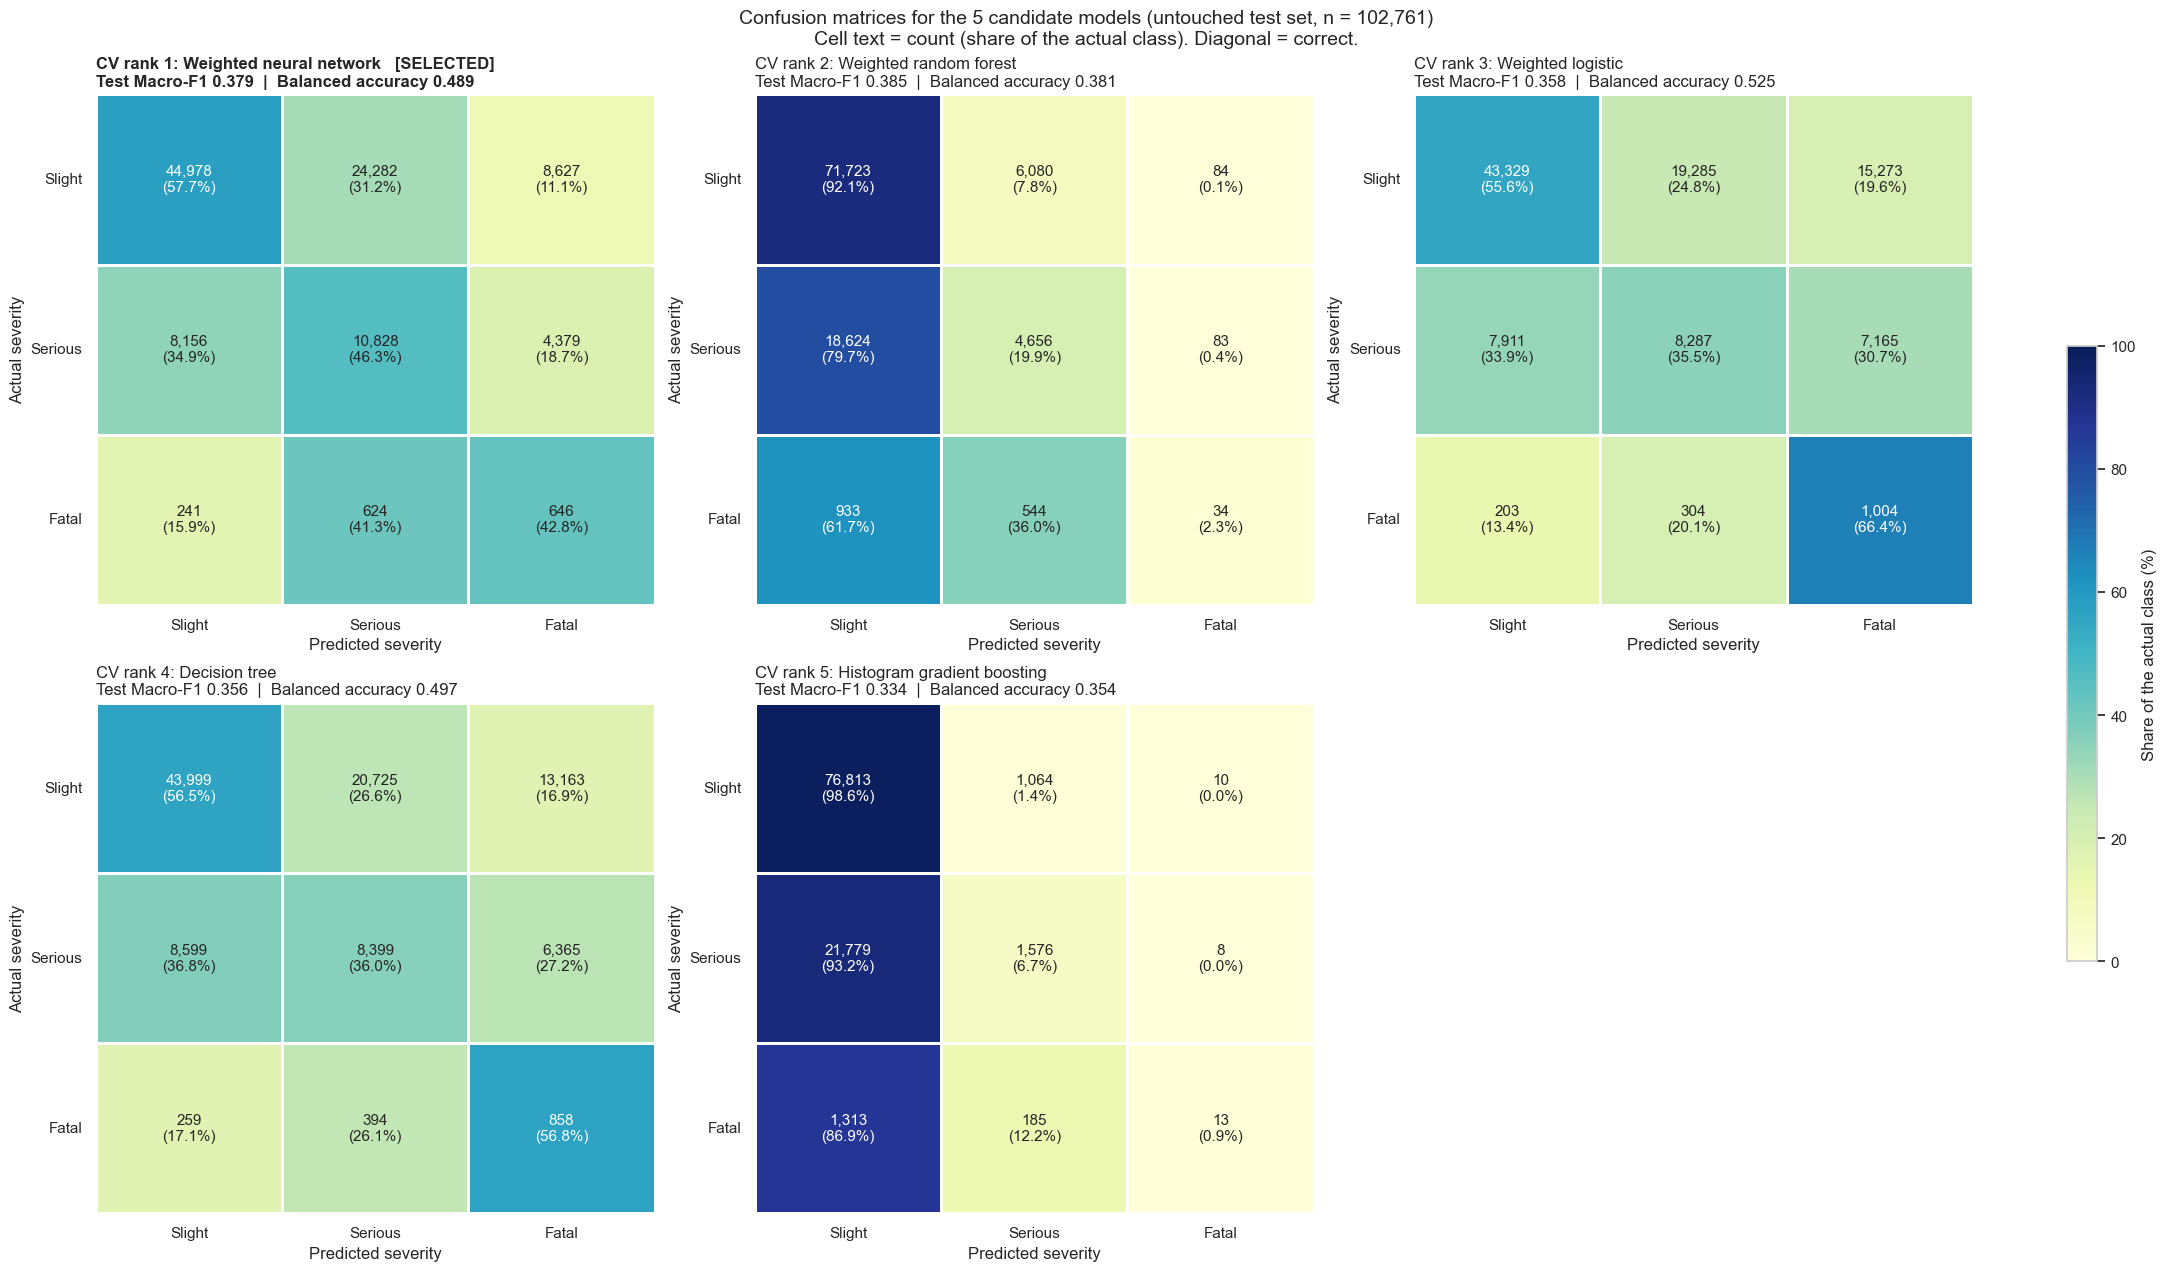

,Model,Correct predictions (%),Slight kept as Slight (%),Serious detected (%),Fatal detected (%),Serious predicted Slight,Fatal predicted Slight,Severe missed (%),Slight false alarms,False-alarm rate (%),Fatal predictions issued,Fatal precision (%)
CV rank,,,,,,,,,,,,
1,Weighted neural network,54.9,57.7,46.3,42.8,"8,156",241,33.8,"32,909",42.3,"13,652",4.7
2,Weighted random forest,74.4,92.1,19.9,2.3,"18,624",933,78.6,"6,164",7.9,201,16.9
3,Weighted logistic,51.2,55.6,35.5,66.4,"7,911",203,32.6,"34,558",44.4,"23,442",4.3
4,Decision tree,51.8,56.5,36.0,56.8,"8,599",259,35.6,"33,888",43.5,"20,386",4.2
5,Histogram gradient boosting,76.3,98.6,6.7,0.9,"21,779","1,313",92.8,"1,074",1.4,31,41.9


In [39]:
# ============================================================
# 8.3 DISPLAY THE CONFUSION MATRICES FOR ALL CANDIDATE MODELS
# Purpose:
# Show, for each model, how the actual Slight, Serious and Fatal test cases
# were distributed across predicted classes. Each cell shows the count and the
# share of that actual class; colour encodes the share so the four matrices
# use one common scale and can be compared directly.
# ============================================================

confusion_tables = {}
confusion_rows = []

n_models = len(candidate_ranking)
n_cols = 3 if n_models > 4 else 2
n_rows = math.ceil(n_models / n_cols)
fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(7.2 * n_cols, 6.3 * n_rows),
    constrained_layout=True,
    squeeze=False,
)
for unused_ax in axes.ravel()[n_models:]:
    unused_ax.axis('off')
for ax, (cv_rank, model_name) in zip(axes.ravel(), candidate_ranking['Model'].items()):
    predictions = test_predictions_by_model[model_name]
    counts = confusion_matrix(yte, predictions, labels=severity_order)
    row_share = counts / counts.sum(axis=1, keepdims=True)
    confusion_tables[model_name] = pd.DataFrame(
        counts,
        index=[f'Actual {label}' for label in severity_order],
        columns=[f'Predicted {label}' for label in severity_order],
    )
    annotations = np.array(
        [
            [f'{counts[r, c]:,}\n({row_share[r, c]:.1%})' for c in range(3)]
            for r in range(3)
        ]
    )
    sns.heatmap(
        row_share * 100,
        annot=annotations,
        fmt='',
        cmap='YlGnBu',
        vmin=0,
        vmax=100,
        cbar=False,
        linewidths=2,
        linecolor='white',
        xticklabels=severity_order,
        yticklabels=severity_order,
        annot_kws={'fontsize': 11},
        ax=ax,
    )
    selected_tag = '   [SELECTED]' if model_name == best_name else ''
    ax.set_title(
        f'CV rank {cv_rank}: {model_name}{selected_tag}\n'
        f"Test Macro-F1 {test_comparison.loc[cv_rank, 'Test Macro-F1']:.3f}  |  "
        f"Balanced accuracy {test_comparison.loc[cv_rank, 'Balanced accuracy']:.3f}",
        fontsize=12,
        loc='left',
        fontweight='bold' if selected_tag else 'normal',
    )
    ax.set_xlabel('Predicted severity')
    ax.set_ylabel('Actual severity')
    ax.tick_params(axis='y', rotation=0)

    severe_actual = counts[1:, :].sum()
    slight_actual = counts[0, :].sum()
    fatal_predicted = counts[:, 2].sum()
    confusion_rows.append(
        {
            'CV rank': cv_rank,
            'Model': model_name,
            'Correct predictions (%)': 100 * np.trace(counts) / counts.sum(),
            'Slight kept as Slight (%)': 100 * row_share[0, 0],
            'Serious detected (%)': 100 * row_share[1, 1],
            'Fatal detected (%)': 100 * row_share[2, 2],
            'Serious predicted Slight': int(counts[1, 0]),
            'Fatal predicted Slight': int(counts[2, 0]),
            'Severe missed (%)': 100 * (counts[1, 0] + counts[2, 0]) / severe_actual,
            'Slight false alarms': int(counts[0, 1] + counts[0, 2]),
            'False-alarm rate (%)': 100 * (counts[0, 1] + counts[0, 2]) / slight_actual,
            'Fatal predictions issued': int(fatal_predicted),
            'Fatal precision (%)': (
                100 * counts[2, 2] / fatal_predicted if fatal_predicted else 0.0
            ),
        }
    )

fig.colorbar(
    axes[0, 0].collections[0],
    ax=axes.ravel()[:n_models].tolist(),
    shrink=0.55,
    label='Share of the actual class (%)',
)
fig.suptitle(
    f'Confusion matrices for the {n_models} candidate models '
    f'(untouched test set, n = {len(yte):,})\n'
    'Cell text = count (share of the actual class). Diagonal = correct.',
    fontsize=14,
)
plt.show()

confusion_summary = pd.DataFrame(confusion_rows).set_index('CV rank')
confusion_summary.to_csv(OUTPUTS / 'confusion_matrix_summary_all_models.csv')
pd.concat(confusion_tables, names=['Model', 'Actual']).to_csv(
    OUTPUTS / 'confusion_matrices_all_models.csv'
)

display(
    confusion_summary.style.format(
        {
            'Correct predictions (%)': '{:.1f}',
            'Slight kept as Slight (%)': '{:.1f}',
            'Serious detected (%)': '{:.1f}',
            'Fatal detected (%)': '{:.1f}',
            'Serious predicted Slight': '{:,.0f}',
            'Fatal predicted Slight': '{:,.0f}',
            'Severe missed (%)': '{:.1f}',
            'Slight false alarms': '{:,.0f}',
            'False-alarm rate (%)': '{:.1f}',
            'Fatal predictions issued': '{:,.0f}',
            'Fatal precision (%)': '{:.1f}',
        }
    ).apply(
        lambda row: [
            'background-color: #EDF8F3; font-weight: bold'
            if row['Model'] == best_name else ''
            for _ in row
        ],
        axis=1,
    )
)

### Interpretation of output 8.3

The confusion matrices give the counts behind the class-level results. The table below summarises them for the 102,761 test records.

| Model | Correct | Severe missed | Slight false alarms | False-alarm rate | Fatal predictions | Fatal precision |
|---|---|---|---|---|---|---|
| Weighted neural network | 54.9% | 33.8% | 32,909 | 42.3% | 13,652 | 4.7% |
| Weighted random forest | 74.4% | 78.6% | 6,164 | 7.9% | 201 | 16.9% |
| Weighted logistic | 51.2% | 32.6% | 34,558 | 44.4% | 23,442 | 4.3% |
| Decision tree | 51.8% | 35.6% | 33,888 | 43.5% | 20,386 | 4.2% |
| Histogram gradient boosting | 76.3% | 92.8% | 1,074 | 1.4% | 31 | 41.9% |

#### Weighted neural network

The neural network classified 44,978 Slight (57.7%), 10,828 Serious (46.3%) and 646 Fatal (42.8%) collisions correctly; its 10,828 correct Serious predictions were the most of any model. Of the actual Fatal collisions, a further 624 were predicted as Serious and 241 as Slight. Among Slight collisions, 24,282 were predicted as Serious and 8,627 as Fatal, giving 32,909 false alarms (42.3%). Overall, 54.9% of its predictions were correct, it missed 33.8% of severe collisions, and 4.7% of its 13,652 Fatal predictions were correct.

#### Weighted random forest

The random forest kept 71,723 Slight collisions (92.1%) correct and raised only 6,164 false alarms (7.9%). However, it predicted 18,624 Serious collisions (79.7%) and 933 Fatal collisions (61.7%) as Slight, and identified only 4,656 Serious (19.9%) and 34 Fatal (2.3%) collisions. Its overall accuracy was 74.4%, it missed 78.6% of severe collisions, and 16.9% of its 201 Fatal predictions were correct.

#### Weighted logistic regression

Weighted logistic regression identified the most Fatal collisions, 1,004 (66.4%), with only 203 predicted as Slight, and it missed the smallest share of severe collisions (32.6%). It also raised the most false alarms, 34,558 (44.4%), including 15,273 Slight collisions predicted as Fatal. It identified 8,287 Serious collisions (35.5%), its overall accuracy was 51.2%, and 4.3% of its 23,442 Fatal predictions were correct.

#### Decision tree

The decision tree identified 858 Fatal (56.8%) and 8,399 Serious (36.0%) collisions, with 33,888 false alarms (43.5%). Its overall accuracy was 51.8%, it missed 35.6% of severe collisions, and 4.2% of its 20,386 Fatal predictions were correct.

#### Histogram gradient boosting

Gradient boosting classified 76,813 Slight collisions (98.6%) correctly and had the highest overall accuracy of the five models (76.3%). It identified only 1,576 Serious (6.7%) and 13 Fatal (0.9%) collisions, however, and predicted 21,779 Serious and 1,313 Fatal collisions as Slight. It missed 92.8% of severe collisions, the highest share of any model.

#### Selection of the final model

The weighted neural network was selected because it had the highest cross-validated Macro-F1 (0.389). Its test results supported the choice on the severe classes:

- it had the highest F1 for both Serious (0.366) and Fatal (0.085) collisions;
- it made the most correct Serious predictions (10,828);
- it missed 33.8% of severe collisions, compared with 78.6% for the weighted random forest.

Compared with the other two models with high severe recall, weighted logistic regression and the decision tree, it achieved:

- a higher test Macro-F1 (0.379 against 0.358 and 0.356);
- higher Serious recall (46.3% against 35.5% and 36.0%);
- a lower false-alarm rate (42.3% against 44.4% and 43.5%);
- higher Fatal precision (4.7% against 4.3% and 4.2%).

Some results favoured other models. The weighted random forest had a higher test Macro-F1 (0.385), higher overall accuracy (74.4% against 54.9%) and a much lower false-alarm rate (7.9% against 42.3%). Weighted logistic regression identified more Fatal collisions (1,004 against 646) and missed a slightly smaller share of severe collisions (32.6% against 33.8%).

The selected model was examined further in Sections 8.4 to 8.6, and the acceptance tests in Section 9.1 were applied to its test results.

In [40]:
# ============================================================
# 8.4 EXPLAIN THE MODEL USING SAFE PERMUTATION IMPORTANCE
# Purpose:
# Use a stratified sample, five repetitions and one worker process to avoid Windows pickling and unnecessary runtime.
# ============================================================

PERMUTATION_SAMPLE_SIZE = min(15_000, len(Xte))

if len(Xte) > PERMUTATION_SAMPLE_SIZE:
    _, X_permutation, _, y_permutation = train_test_split(
        Xte,
        yte,
        test_size=PERMUTATION_SAMPLE_SIZE,
        stratify=yte,
        random_state=RANDOM_STATE,
    )
else:
    X_permutation = Xte.copy()
    y_permutation = yte.copy()

permutation_result = permutation_importance(
    estimator=best_model,
    X=X_permutation,
    y=y_permutation,
    scoring='f1_macro',
    n_repeats=3,
    n_jobs=1,
    random_state=RANDOM_STATE,
)

importance = (
    pd.DataFrame(
        {
            'Feature': X_permutation.columns,
            'Mean importance': permutation_result.importances_mean,
            'Importance variation': permutation_result.importances_std,
        }
    )
    .sort_values('Mean importance', ascending=False)
    .reset_index(drop=True)
)
importance.to_csv(OUTPUTS / 'permutation_importance.csv', index=False)
display(importance.head(20).style.format({'Mean importance': '{:.4f}', 'Importance variation': '{:.4f}'}))


,Feature,Mean importance,Importance variation
0,driver_age_mean,0.0123,0.0008
1,vehicle_type_first,0.0091,0.0007
2,vehicle_manoeuvre_first,0.0077,0.0025
3,time_band,0.0073,0.0010
4,driver_age_min,0.0044,0.0001
5,speed_limit,0.0043,0.0011
6,trunk_road_flag,0.0038,0.0013
7,road_type,0.0035,0.0013
8,junction_detail,0.0030,0.0012
9,engine_cc_mean,0.0028,0.0006


### Interpretation of output 8.4

Permutation importance was calculated for the neural network on a stratified sample of 15,000 test records with three repeats. The largest drops in Macro-F1 came from shuffling mean driver age (0.0123), first-vehicle type (0.0091), first-vehicle manoeuvre (0.0077) and time band (0.0073). These were followed by minimum driver age (0.0044), speed limit (0.0043), trunk road flag (0.0038), road type (0.0035), junction detail (0.0030) and mean engine size (0.0028). Time band ranked well above the numeric hour, whose importance was 0.0003.

From the thirteenth predictor (light conditions, 0.0012) downwards, each importance value was smaller than or equal to its variation. First-vehicle type and manoeuvre, ranked second and third here, were also the two strongest driver and vehicle associations in Section 6.2. The ten highest-ranked predictors were carried into the management matrix in Section 8.4A.

In [41]:
# ============================================================
# 8.4A CREATE THE MANAGEMENT INTERPRETATION MATRIX
# Purpose:
# Translate the most influential predictors into areas for further review while explicitly avoiding causal claims.
# ============================================================
def management_area(feature_name):
    name = feature_name.lower()
    if any(word in name for word in [
        'road', 'junction', 'speed', 'carriageway', 'crossing'
    ]):
        return 'Road design and infrastructure review'
    if any(word in name for word in ['light', 'weather', 'surface']):
        return 'Visibility and environmental-condition review'
    if any(word in name for word in [
        'hour', 'time', 'day', 'month', 'weekend'
    ]):
        return 'Time-based deployment and enforcement review'
    if any(word in name for word in [
        'driver', 'vehicle', 'engine', 'manoeuvre'
    ]):
        return 'Driver, vehicle and enforcement review'
    return 'Further road-safety investigation'

management_matrix = importance.head(10).copy()
management_matrix['Management review area'] = (
    management_matrix['Feature'].apply(management_area)
)
management_matrix['Interpretation caution'] = (
    'Predictive reliance is not evidence that the feature caused severity.'
)
management_matrix.to_csv(
    OUTPUTS / 'management_interpretation_matrix.csv',
    index=False,
)
display(management_matrix)


,Feature,Mean importance,Importance variation,Management review area,Interpretation caution
0,driver_age_mean,0.0123,0.0008,"Driver, vehicle and enforcement review",Predictive reliance is not evidence that the f...
1,vehicle_type_first,0.0091,0.0007,"Driver, vehicle and enforcement review",Predictive reliance is not evidence that the f...
2,vehicle_manoeuvre_first,0.0077,0.0025,"Driver, vehicle and enforcement review",Predictive reliance is not evidence that the f...
3,time_band,0.0073,0.0010,Time-based deployment and enforcement review,Predictive reliance is not evidence that the f...
4,driver_age_min,0.0044,0.0001,"Driver, vehicle and enforcement review",Predictive reliance is not evidence that the f...
5,speed_limit,0.0043,0.0011,Road design and infrastructure review,Predictive reliance is not evidence that the f...
6,trunk_road_flag,0.0038,0.0013,Road design and infrastructure review,Predictive reliance is not evidence that the f...
7,road_type,0.0035,0.0013,Road design and infrastructure review,Predictive reliance is not evidence that the f...
8,junction_detail,0.0030,0.0012,Road design and infrastructure review,Predictive reliance is not evidence that the f...
9,engine_cc_mean,0.0028,0.0006,"Driver, vehicle and enforcement review",Predictive reliance is not evidence that the f...


### Interpretation of output 8.4A

The ten most important predictors were grouped by management review area:

| Review area | Predictors |
|---|---|
| Driver, vehicle and enforcement review | mean driver age, first-vehicle type, first-vehicle manoeuvre, minimum driver age and mean engine size |
| Road design and infrastructure review | speed limit, trunk road flag, road type and junction detail |
| Time-based deployment and enforcement review | time band |

Each row carried the caution that predictive reliance is not evidence that a feature caused severity. The matrix was saved to `outputs/management_interpretation_matrix.csv`.

In [42]:
# ============================================================
# 8.5 PROFILE HIGH-CONSEQUENCE MODEL ERRORS
# Purpose:
# Identify actual Serious or Fatal collisions predicted as Slight and compare selected characteristics across missed and detected severe cases.
# ============================================================

errors = Xte.copy()
errors['Actual severity'] = yte.to_numpy()
errors['Predicted severity'] = test_predictions

severe_cases = errors[
    errors['Actual severity'].isin(['Fatal', 'Serious'])
].copy()
severe_cases['Detection result'] = np.where(
    severe_cases['Predicted severity'].eq('Slight'),
    'Missed severe case',
    'Detected as non-Slight',
)

severe_summary = (
    severe_cases['Detection result']
    .value_counts()
    .rename_axis('Detection result')
    .reset_index(name='Cases')
)
severe_summary['Share'] = severe_summary['Cases'] / severe_summary['Cases'].sum()
display(severe_summary.style.format({'Cases': '{:,.0f}', 'Share': '{:.1%}'}))
severe_cases.to_csv(OUTPUTS / 'severe_case_predictions.csv', index=False)


,Detection result,Cases,Share
0,Detected as non-Slight,"16,477",66.2%
1,Missed severe case,"8,397",33.8%


### Interpretation of output 8.5

Of the actual Serious and Fatal collisions in the test set, the neural network classified 16,477 (66.2%) as Serious or Fatal and 8,397 (33.8%) as Slight. The missed cases correspond to the 8,156 Serious and 241 Fatal collisions in the "Predicted Slight" column of its confusion matrix. The case-level predictions were saved to `outputs/severe_case_predictions.csv` and profiled in Section 8.5A.

In [43]:
# ============================================================
# 8.5A PROFILE MISSED AND DETECTED SEVERE CASES
# Purpose:
# Compare numeric summaries and the most common categorical values for missed versus detected Serious/Fatal collisions.
# ============================================================
profile_features = available(
    severe_cases,
    [
        'speed_limit', 'hour', 'driver_age_mean',
        'light_conditions', 'road_surface_conditions',
        'urban_or_rural_area', 'vehicle_type_first',
    ],
)
numeric_profile_features = {'speed_limit', 'hour', 'driver_age_mean'}
numeric_profiles = []
categorical_profiles = []

for feature in profile_features:
    if feature in numeric_profile_features:
        summary = (
            severe_cases.groupby('Detection result')[feature]
            .agg(['count', 'mean', 'median'])
            .reset_index()
        )
        summary.insert(0, 'Feature', feature)
        numeric_profiles.append(summary)
    else:
        summary = (
            severe_cases.groupby(
                ['Detection result', feature],
                dropna=False,
            )
            .size()
            .rename('Cases')
            .reset_index()
            .sort_values(
                ['Detection result', 'Cases'],
                ascending=[True, False],
            )
            .groupby('Detection result', as_index=False)
            .head(5)
            .rename(columns={feature: 'Category'})
        )
        summary.insert(0, 'Feature', feature)
        categorical_profiles.append(summary)

if numeric_profiles:
    numeric_error_profile = pd.concat(numeric_profiles, ignore_index=True)
    numeric_error_profile.to_csv(
        OUTPUTS / 'severe_error_numeric_profile.csv',
        index=False,
    )
    display(numeric_error_profile)

if categorical_profiles:
    categorical_error_profile = pd.concat(
        categorical_profiles,
        ignore_index=True,
    )
    categorical_error_profile.to_csv(
        OUTPUTS / 'severe_error_categorical_profile.csv',
        index=False,
    )
    display(categorical_error_profile)


,Feature,Detection result,count,mean,median
0,speed_limit,Detected as non-Slight,16477,39.9448,30.0000
1,speed_limit,Missed severe case,8397,34.0669,30.0000
2,hour,Detected as non-Slight,16477,13.8925,15.0000
3,hour,Missed severe case,8397,13.6584,14.0000
4,driver_age_mean,Detected as non-Slight,15859,43.2484,42.0000
5,driver_age_mean,Missed severe case,7987,39.9653,38.5000


,Feature,Detection result,Category,Cases
0,light_conditions,Detected as non-Slight,1,10683
1,light_conditions,Detected as non-Slight,4,3695
2,light_conditions,Detected as non-Slight,6,1718
3,light_conditions,Detected as non-Slight,7,205
4,light_conditions,Detected as non-Slight,5,176
5,light_conditions,Missed severe case,1,6450
6,light_conditions,Missed severe case,4,1583
7,light_conditions,Missed severe case,6,193
8,light_conditions,Missed severe case,7,127
9,light_conditions,Missed severe case,5,44


### Interpretation of output 8.5A

The detected severe cases had a higher mean speed limit than the missed ones (39.94 against 34.07), although the median was 30 in both groups, and a higher mean driver age (43.25 against 39.97). The mean hour was similar in both groups (13.89 and 13.66).

The category profiles showed where the misses were concentrated:

- Urban collisions (code 1) made up 6,292 of the 8,397 missed cases, and vehicle type code 9 made up 6,655.
- Daylight (code 1) was the most common light condition in both groups, with 10,683 detected and 6,450 missed cases.
- Collisions in darkness with no lighting (code 6) appeared 1,718 times among the detected cases but only 193 times among the missed cases.
- Vehicle type code 5 was among the five most common codes for detected cases (1,557) but not for missed cases.
- Dry and wet or damp were the two most common road surfaces in both groups.

In [44]:
# ============================================================
# 8.6 PERFORM LATEST-YEAR ROBUSTNESS TESTING
# Purpose:
# Train the selected pipeline on earlier years and test it on the latest year to assess stability over time.
# ============================================================

if 'calendar_year' not in analysis.columns:
    print('Latest-year validation skipped because calendar year is unavailable.')
else:
    temporal_data = analysis[features + ['severity_label', 'calendar_year']].dropna(
        subset=['severity_label', 'calendar_year']
    ).copy()
    latest_year = int(temporal_data['calendar_year'].max())
    temporal_train = temporal_data[temporal_data['calendar_year'] < latest_year].copy()
    temporal_test = temporal_data[temporal_data['calendar_year'] == latest_year].copy()

    for column in categorical_features:
        temporal_train[column] = (
            temporal_train[column]
            .astype(object)
            .where(temporal_train[column].notna(), 'Missing')
            .map(str)
        )
        temporal_test[column] = (
            temporal_test[column]
            .astype(object)
            .where(temporal_test[column].notna(), 'Missing')
            .map(str)
        )

    temporal_model = clone(models[best_name])
    with warnings.catch_warnings(record=True) as temporal_warnings:
        warnings.simplefilter('always')
        temporal_model.fit(
            temporal_train[features],
            temporal_train['severity_label'],
            **fit_params_for(best_name, temporal_train['severity_label']),
        )
    temporal_predictions = temporal_model.predict(temporal_test[features])

    temporal_metrics = pd.DataFrame(
        [
            {
                'Test year': latest_year,
                'Training records': len(temporal_train),
                'Test records': len(temporal_test),
                'Fit warnings': len(temporal_warnings),
                'Macro-F1': f1_score(
                    temporal_test['severity_label'], temporal_predictions, average='macro'
                ),
                'Balanced accuracy': balanced_accuracy_score(
                    temporal_test['severity_label'], temporal_predictions
                ),
                'Serious recall': recall_score(
                    temporal_test['severity_label'], temporal_predictions,
                    labels=['Serious'], average='macro', zero_division=0
                ),
                'Fatal recall': recall_score(
                    temporal_test['severity_label'], temporal_predictions,
                    labels=['Fatal'], average='macro', zero_division=0
                ),
            }
        ]
    )
    temporal_metrics.to_csv(OUTPUTS / 'temporal_holdout_metrics.csv', index=False)
    display(temporal_metrics)

,Test year,Training records,Test records,Fit warnings,Macro-F1,Balanced accuracy,Serious recall,Fatal recall
0,2025,412276,101525,1,0.3725,0.4870,0.5257,0.4171


### Interpretation of output 8.6

When the neural network was trained on 412,276 collisions from the years before 2025 and tested on 101,525 collisions from 2025, it recorded one fit warning and achieved:

| Measure | 2025 holdout | Random test split (Section 8.1) |
|---|---|---|
| Macro-F1 | 0.3725 | 0.3790 |
| Balanced accuracy | 0.487 | 0.4895 |
| Serious recall | 0.5257 | 0.4635 |
| Fatal recall | 0.4171 | 0.4275 |

Macro-F1, balanced accuracy and Fatal recall were slightly lower in 2025, while Serious recall was higher. The results on the later year were therefore close to those from the random split.

# 9. CRISP-DM Phase 6: Deployment and Governance

In [45]:
# ============================================================
# 9.1 APPLY THE MODEL ACCEPTANCE GATE
# Purpose:
# Compare the selected model with documented minimum conditions before permitting stakeholder-facing deployment.
# ============================================================

dummy_macro_f1 = cv_results.loc[
    cv_results['Model'] == 'Dummy majority', 'Macro-F1'
].iloc[0]
selected_macro_f1 = candidate_ranking.iloc[0]['Macro-F1']

acceptance_criteria = {
    'Performs better than the no-skill model': selected_macro_f1 > dummy_macro_f1,
    'Macro-F1 is at least 0.60': final_metrics['Macro-F1'] >= 0.60,
    'Balanced accuracy is at least 0.60': final_metrics['Balanced accuracy'] >= 0.60,
    'Serious recall is at least 0.60': final_metrics['Serious recall'] >= 0.60,
    'Fatal recall is at least 0.60': final_metrics['Fatal recall'] >= 0.60,
}

acceptance_table = pd.DataFrame(
    {
        'Acceptance test': acceptance_criteria.keys(),
        'Passed': acceptance_criteria.values(),
    }
)
all_passed = bool(acceptance_table['Passed'].all())
final_decision = (
    'Suitable for a research demonstration'
    if all_passed
    else 'Further model improvement recommended'
)
acceptance_table['Overall decision'] = final_decision
acceptance_table.to_csv(OUTPUTS / 'model_acceptance_gate.csv', index=False)

display(acceptance_table)
print('Final decision:', final_decision)


,Acceptance test,Passed,Overall decision
0,Performs better than the no-skill model,True,Further model improvement recommended
1,Macro-F1 is at least 0.60,False,Further model improvement recommended
2,Balanced accuracy is at least 0.60,False,Further model improvement recommended
3,Serious recall is at least 0.60,False,Further model improvement recommended
4,Fatal recall is at least 0.60,False,Further model improvement recommended


Final decision: Further model improvement recommended


### Interpretation of output 9.1

The selected model passed one of the five acceptance tests. Its cross-validated Macro-F1 (0.389) was higher than that of the no-skill baseline (0.287). However, its test Macro-F1 (0.3790), balanced accuracy (0.4895), Serious recall (0.4635) and Fatal recall (0.4275) all fell below the 0.60 threshold, and the decision printed was "Further model improvement recommended".

None of the five candidates in Section 8.1 reached 0.60 on Macro-F1 (the highest was 0.385) or on balanced accuracy (the highest was 0.525). The decision was written into the model metadata and contract (Sections 9.2 and 9.3) and reported in the executive summary (Section 9.4).

In [46]:
# ============================================================
# 9.2 SAVE THE FITTED PIPELINE AND METADATA
# Purpose:
# Persist the exact preprocessing-and-model pipeline used in evaluation together with its fields, metrics, warnings and scope.
# ============================================================

model_path = MODELS / 'stats19_severity_model.joblib'
metadata_path = MODELS / 'metadata.json'

joblib.dump(best_model, model_path)

metadata = {
    'model': best_name,
    'candidate_models': CANDIDATE_MODELS,
    'additional_models': ADDITIONAL_MODELS,
    'selection_rule': 'Highest three-fold cross-validated Macro-F1',
    'candidate_test_comparison': json.loads(
        test_comparison.reset_index().to_json(orient='records')
    ),
    'features': features,
    'numeric_features': numeric_features,
    'categorical_features': categorical_features,
    'metrics': final_metrics,
    'random_state': RANDOM_STATE,
    'acceptance_decision': final_decision,
    'scope': (
        'Predicts severity conditional on a recorded personal-injury collision. '
        'It does not predict whether a collision will occur.'
    ),
}
metadata_path.write_text(json.dumps(metadata, indent=2), encoding='utf-8')

print('Saved model:', model_path)
print('Saved metadata:', metadata_path)


Saved model: c:\Users\Isaac\Desktop\Capstone_backup\models\stats19_severity_model.joblib
Saved metadata: c:\Users\Isaac\Desktop\Capstone_backup\models\metadata.json


### Interpretation of output 9.2

The fitted neural network pipeline was saved to `models/stats19_severity_model.joblib`, and its metadata to `models/metadata.json`. The metadata recorded the selected model, the candidate models, the selection rule, the test comparison of all candidates, the features, the final metrics, the random seed, the acceptance decision and the scope statement. These files were used to build the application contract in Section 9.3.

In [47]:
# ============================================================
# 9.3 CREATE THE APPLICATION INPUT CONTRACT
# Purpose:
# Record the expected input fields, data types, default values, category examples and model classes for the prediction application.
# ============================================================

feature_contract = []

for feature in features:
    if feature in numeric_features:
        default_value = pd.to_numeric(Xtr[feature], errors='coerce').median()
        feature_contract.append(
            {
                'feature': feature,
                'dtype': 'numeric',
                'default': float(default_value) if pd.notna(default_value) else 0.0,
                'category_examples': [],
            }
        )
    else:
        examples = (
            Xtr[feature]
            .dropna()
            .astype(str)
            .value_counts()
            .head(30)
            .index.tolist()
        )
        feature_contract.append(
            {
                'feature': feature,
                'dtype': 'categorical',
                'default': examples[0] if examples else 'Unknown',
                'category_examples': examples,
            }
        )

model_contract = {
    'model_file': model_path.name,
    'target': 'severity_label',
    'classes': list(best_model.classes_),
    'features': feature_contract,
    'scope_warning': metadata['scope'],
    'operational_warning': final_decision,
}

contract_path = MODELS / 'model_contract.json'
contract_path.write_text(json.dumps(model_contract, indent=2), encoding='utf-8')
print('Saved model contract:', contract_path)


Saved model contract: c:\Users\Isaac\Desktop\Capstone_backup\models\model_contract.json


### Interpretation of output 9.3

The application contract was saved to `models/model_contract.json`. It listed each of the 27 predictors with its input type, default value and category examples, together with the model classes, the scope warning and the acceptance decision from Section 9.1. The prediction application reads its input fields, defaults and warnings from this file.

In [48]:
# ============================================================
# 9.4 GENERATE THE EXECUTIVE EVIDENCE SUMMARY
# Purpose:
# Create a concise summary from the executed model results and acceptance decision so the conclusion cannot contradict the evidence.
# ============================================================
executive_evidence = pd.DataFrame(
    [
        {'Finding': 'Models compared', 'Result': f'{len(SHORTLISTED_MODELS)} shortlisted models + weighted neural network + no-skill baseline'},
        {'Finding': 'Selection rule', 'Result': 'Highest cross-validated Macro-F1'},
        {'Finding': 'Selected model', 'Result': best_name},
        {'Finding': 'Overall accuracy', 'Result': f"{final_metrics['Overall accuracy']:.1%}"},
        {'Finding': 'Balanced accuracy', 'Result': f"{final_metrics['Balanced accuracy']:.1%}"},
        {'Finding': 'Macro-F1', 'Result': f"{final_metrics['Macro-F1']:.3f}"},
        {'Finding': 'Serious recall', 'Result': f"{final_metrics['Serious recall']:.1%}"},
        {'Finding': 'Fatal recall', 'Result': f"{final_metrics['Fatal recall']:.1%}"},
        {'Finding': 'Deployment decision', 'Result': final_decision},
    ]
)
executive_evidence.to_csv(
    OUTPUTS / 'executive_evidence_summary.csv',
    index=False,
)
display(executive_evidence)

print(
    'The project should be presented as stakeholder-ready only when all '
    'acceptance tests pass. Otherwise, it remains a research demonstration.'
)


,Finding,Result
0,Models compared,4 shortlisted models + weighted neural network...
1,Selection rule,Highest cross-validated Macro-F1
2,Selected model,Weighted neural network
3,Overall accuracy,54.9%
4,Balanced accuracy,48.9%
5,Macro-F1,0.379
6,Serious recall,46.3%
7,Fatal recall,42.8%
8,Deployment decision,Further model improvement recommended


The project should be presented as stakeholder-ready only when all acceptance tests pass. Otherwise, it remains a research demonstration.


### Interpretation of output 9.4

The executive summary recorded the final position. Four shortlisted models, the weighted neural network and a no-skill baseline were compared, and the weighted neural network was selected on the highest cross-validated Macro-F1. On the test set it reached:

| Measure | Result |
|---|---|
| Overall accuracy | 54.9% |
| Balanced accuracy | 48.9% |
| Macro-F1 | 0.379 |
| Serious recall | 46.3% |
| Fatal recall | 42.8% |

The deployment decision was "Further model improvement recommended". The selected model's overall accuracy was below the 0.758 that the Dummy baseline reached in cross-validation. As not all of the acceptance tests were passed, the printed rule meant that the project was presented as a research demonstration rather than a stakeholder-ready tool.

# 10. Project Findings, Conclusion and Recommendations

## 10.1 Summary of Findings

The study used 513,801 collision records (44 fields), 937,265 vehicle records (32 fields) and 652,821 casualty records (24 fields). Collision keys were unique, and both the vehicle and casualty records linked to collisions at 100.00%. Blank values occurred only in four coordinate fields (53 records each), while 59 fields contained negative administrative codes.

The target was strongly imbalanced, with 389,435 Slight (75.8%), 116,813 Serious (22.7%) and 7,553 Fatal (1.5%) collisions. The highest Serious/Fatal shares were found:

| Category | Serious/Fatal share |
|---|---|
| Darkness with no lighting | 34.95% |
| Speed limit of 60 | 34.49% |
| Rural areas (urban areas: 21.69%) | 29.36% |
| Single carriageways | 25.94% |

The unknown categories had the lowest shares in road type, junction detail, weather and road surface. The Greater London window contained 26.6% of mapped Slight collisions, 17.8% of Serious collisions and 8.2% of Fatal collisions.

All tested variables were significant after correction: 13 of 13 for H1, 3 of 3 for H2, 6 of 6 for H3 and 9 of 9 for H4. The largest Cramér's V values were:

| Variable | Cramér's V |
|---|---|
| Casualty type | 0.1613 |
| First-vehicle manoeuvre | 0.1175 |
| First-vehicle type | 0.1082 |
| Speed limit | 0.0904 |
| Hour | 0.0496 |

The largest standardised residuals were +48.99 for Fatal collisions at a speed limit of 60 and +46.16 for Fatal collisions in rural areas.

## 10.2 Machine-Learning Results

| Model | CV Macro-F1 | Test Macro-F1 | Balanced accuracy | Overall accuracy | Serious recall | Fatal recall | Severe missed | False-alarm rate |
|---|---|---|---|---|---|---|---|---|
| Weighted neural network (selected) | 0.389 | 0.379 | 0.489 | 0.549 | 46.3% | 42.8% | 33.8% | 42.3% |
| Weighted random forest | 0.368 | 0.385 | 0.381 | 0.744 | 19.9% | 2.3% | 78.6% | 7.9% |
| Weighted logistic | 0.357 | 0.358 | 0.525 | 0.512 | 35.5% | 66.4% | 32.6% | 44.4% |
| Decision tree | 0.349 | 0.356 | 0.497 | 0.518 | 36.0% | 56.8% | 35.6% | 43.5% |
| Histogram gradient boosting | 0.329 | 0.334 | 0.354 | 0.763 | 6.7% | 0.9% | 92.8% | 1.4% |
| Dummy majority (baseline, CV only) | 0.287 | n/a | 0.333 | 0.758 | n/a | n/a | n/a | n/a |

The weighted neural network was selected on the highest cross-validated Macro-F1 (0.389). On the test set it had the highest Serious F1 (0.366) and Fatal F1 (0.085) of the five candidates. It correctly classified 10,828 of 23,363 Serious and 646 of 1,511 Fatal collisions, and it predicted 8,397 severe collisions (33.8%) as Slight.

Some other results favoured different models. The weighted random forest achieved the highest test Macro-F1 (0.385) with a false-alarm rate of 7.9%. Weighted logistic regression had the highest Fatal recall (66.4%) and balanced accuracy (0.525). Histogram gradient boosting had the highest overall accuracy (0.763).

On the 2025 holdout, the selected model recorded:

| Measure | Result |
|---|---|
| Macro-F1 | 0.3725 |
| Balanced accuracy | 0.487 |
| Serious recall | 0.5257 |
| Fatal recall | 0.4171 |

## 10.3 Hypothesis Conclusions

- **H1** was supported. All 13 road and environment variables were significant after correction, and speed limit showed the largest Cramér's V (0.0904).
- **H2** was supported. All 3 driver and vehicle variables were significant, led by first-vehicle manoeuvre (0.1175).
- **H3** was supported. All 6 temporal variables were significant, led by hour (0.0496).
- **H4** was supported. All 9 casualty variables were significant, led by casualty type (0.1613).
- **H5** was supported. All five candidates exceeded the baseline's cross-validated Macro-F1 (0.287) and balanced accuracy (0.333).
- **H6** was supported within the models tested:
  - The four weighted candidates reached cross-validated balanced accuracies of 0.370 to 0.526, compared with 0.352 for unweighted gradient boosting.
  - Their test Fatal recall ranged from 2.3% to 66.4%, against 0.9% for gradient boosting.
- **H7** was supported for the neural network and the random forest. Both outperformed the linear benchmark, weighted logistic regression, on Macro-F1:

  | Model | CV Macro-F1 | Test Macro-F1 |
  |---|---|---|
  | Weighted neural network | 0.389 | 0.379 |
  | Weighted random forest | 0.368 | 0.385 |
  | Weighted logistic (linear) | 0.357 | 0.358 |

  The decision tree (0.349 and 0.356) and gradient boosting (0.329 and 0.334) did not.

## 10.4 Explainability and Management Implications

The selected model relied most on mean driver age (0.0123), first-vehicle type (0.0091), first-vehicle manoeuvre (0.0077) and time band (0.0073). Of the ten most important predictors, five fell under driver and vehicle review, four under road design and infrastructure review, and one under time-based review. The management matrix carried the caution that predictive reliance is not evidence that a feature caused severity.

The missed severe cases were concentrated in urban collisions (6,292 of the 8,397 misses) and in vehicle type code 9 (6,655). Collisions in darkness with no lighting appeared 1,718 times among the detected severe cases but only 193 times among the missed ones.

## 10.5 Conclusion

The notebook completed each stage of the CRISP-DM process: data acquisition and quality checks; descriptive, spatial and statistical analysis; model comparison and test-set evaluation; explainability, error profiling and a 2025 holdout; an acceptance gate; and model persistence.

The selected model passed one of the five acceptance tests, and the decision recorded was "Further model improvement recommended". In line with the rule printed in Section 9.4, the project is presented as a research demonstration rather than an operational tool.

## 10.6 Recommendations

1. **Improve severe recall without excessive false alarms.** Further work should aim to raise Serious and Fatal recall without the current false-alarm rate. The selected model missed 33.8% of severe collisions while flagging 42.3% of Slight collisions as severe, whereas the weighted random forest had a false-alarm rate of 7.9% but missed 78.6%. Decision thresholds and combinations of the two models could be tested between these two results.
2. **Summarise all vehicles involved.** The missed severe cases were concentrated in urban collisions (6,292 of 8,397) and in vehicle type code 9 (6,655). As the current vehicle features describe only the first vehicle in each collision (Section 6.1), collision-level summaries covering all the vehicles involved should be added and tested.
3. **Judge further work against the same gate.** No candidate reached 0.60 for Macro-F1 (highest 0.385) or balanced accuracy (highest 0.525). Any further feature engineering or tuning should be judged against the same acceptance gate.
4. **Review the neural network's training settings.** The neural network produced one fit warning in Section 8.1 and another in Section 8.6, so its training settings should be reviewed before the next comparison.
5. **Report descriptive results as shares.** Descriptive results should continue to be reported as shares of recorded collisions, in line with the rule printed in Section 4.8.

## 10.7 Limitations

- **Recorded collisions only.** The descriptive results describe recorded collisions only; they are not exposure-adjusted risks and do not prove causation (Section 4.8).
- **Predictive reliance.** The importance results show predictive reliance and are not evidence that a feature caused severity (Section 8.4A).
- **Acceptance gate.** The selected model passed one of the five acceptance tests and predicted 33.8% of severe test collisions as Slight.
- **First vehicle only.** Vehicle information was summarised to collision level using first-vehicle attributes and averages.
- **Descriptive maps.** Coordinates were used only for the descriptive maps, and the London figures refer to a rectangular map window.